# ITAI Midterm: Creating Images with Diffusion Models
**Student:** Trilok Kalani  |  **Course:** ITAI 2376  |  **Notebook:** `MD_Notebook_Trilok_Kalani_ITAI.ipynb`

This notebook implements a class-conditional DDPM (denoising diffusion probabilistic model) with a U-Net noise predictor, trains it, samples from it, and evaluates the samples with a trained classifier and with CLIP.

**How to run:** Colab, Runtime > Change runtime type > GPU, then Runtime > Run all. Choose the dataset in the config cell (`DATASET`). Everything else adapts.

**Mapping to the assignment rubric**

| Rubric item | Section in this notebook |
|---|---|
| a. Dataset setup (15%) | 1 |
| b. Model architecture: `GELUConvBlock`, `UpBlock`, UNet forward, time + class conditioning (25%) | 3 |
| c. Diffusion process: forward noising, reverse sampling, training step (20%) | 2, 4 |
| d. Training and evaluation (20%) | 5, 6 |
| e. CLIP evaluation (bonus 10%) | 8 |
| Bonus challenges | 9 |

> **Note on the template.** The instructor notebook `L09_Diffusion_student_notebook_ITAI_2376.ipynb` was not available when this was written. The function and class names here (`GELUConvBlock`, `UpBlock`, `q_sample`, `train_step`, ...) follow the assignment text, so each piece can be ported into the matching "Enter your code here" cell.

## 0. Setup

In [1]:
%pip install -q transformers matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, math, time, json, copy, random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
import torchvision, torchvision.transforms as T
from torchvision.utils import make_grid

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only (training will be slow)")

device: cpu | CPU only (training will be slow)


### Config
Choose ONE dataset. Per-dataset defaults come from the assignment's resource guidance (MNIST / Fashion-MNIST ~15-30 min on Colab, CIFAR-10 ~1-2 h).

If you hit **GPU out-of-memory**, in this order: lower `bs`, choose a simpler dataset, lower `base` (fewer U-Net channels). If training is unstable, check `lr`, confirm the data is normalised to [-1, 1] (section 1 asserts this), and look at the gradient-norm plot in section 6.

In [3]:
DATASET     = "MNIST"     # "MNIST" | "FashionMNIST" | "CIFAR10"
SMOKE_TEST  = False       # True = tiny/fast run only to check the code executes. Leave False for real results.
RESUME      = True        # resume from checkpoints/<DATASET>_last.pt if it exists
RUN_CLIP    = True        # section 8 (bonus)

CFGS = {
    "MNIST":        dict(ch=1, size=28, base=64,  epochs=20, bs=128, lr=2e-4),
    "FashionMNIST": dict(ch=1, size=28, base=64,  epochs=25, bs=128, lr=2e-4),
    "CIFAR10":      dict(ch=3, size=32, base=128, epochs=60, bs=128, lr=2e-4),
}
CLASS_NAMES = {
    "MNIST": [str(i) for i in range(10)],
    "FashionMNIST": ["t-shirt/top", "trouser", "pullover", "dress", "coat", "sandal", "shirt", "sneaker", "bag", "ankle boot"],
    "CIFAR10": ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"],
}
PROMPT_TMPL = {"MNIST": "a handwritten digit {}", "FashionMNIST": "a photo of a {}", "CIFAR10": "a photo of a {}"}

cfg = dict(CFGS[DATASET])
CH, SIZE, BASE, EPOCHS, BS, LR = cfg["ch"], cfg["size"], cfg["base"], cfg["epochs"], cfg["bs"], cfg["lr"]
NUM_CLASSES = 10
NAMES = CLASS_NAMES[DATASET]
T_STEPS = 1000                # number of diffusion steps
N_PER_CLASS = 20              # samples per class used for evaluation
BON_N = 8                     # candidates per class for CLIP best-of-N

if SMOKE_TEST:
    BASE, EPOCHS, T_STEPS, N_PER_CLASS, BON_N, BS = 16, 1, 40, 2, 2, 32

# The run saved in this notebook was done on a CPU-only machine (no GPU), so I used a smaller U-Net
# (base 32 channels instead of 64), 10 epochs instead of 20, and 10 samples per class for evaluation.
# T stays at 1000. On a Colab GPU the full config above runs as-is.
CPU_RUN = (device.type == "cpu") and not SMOKE_TEST
if CPU_RUN:
    BASE, EPOCHS, N_PER_CLASS = 32, 10, 10

SNAP_EPOCHS = sorted({1, 3, 5, EPOCHS // 2, EPOCHS} & set(range(1, EPOCHS + 1)))
os.makedirs("checkpoints", exist_ok=True); os.makedirs("figures", exist_ok=True)
RESULTS = {"dataset": DATASET, "epochs": EPOCHS, "T": T_STEPS, "base_channels": BASE, "batch_size": BS, "lr": LR}

def savefig(name):
    plt.savefig(f"figures/{DATASET}_{name}.png", dpi=150, bbox_inches="tight")
print(DATASET, cfg, "| T =", T_STEPS, "| snapshot epochs:", SNAP_EPOCHS)

MNIST {'ch': 1, 'size': 28, 'base': 64, 'epochs': 20, 'bs': 128, 'lr': 0.0002} | T = 1000 | snapshot epochs: [1, 3, 5, 10]


## 1. Dataset setup and preparation (rubric a)

**Why [-1, 1]?** The forward process adds N(0, I) noise. If the clean data lives in [0, 1] its mean is not zero and the signal/noise balance in the schedule is off. Scaling to [-1, 1] centres the data so `sqrt(abar_t) * x0` and the unit-variance noise live on comparable scales, and the sampler's final output is clipped to the same range.

**Split:** 55,000 train / 5,000 validation carved from the official training set with a fixed seed (45,000 / 5,000 for CIFAR-10). The official test set is kept untouched for the classifier and CLIP baselines. Validation loss is computed with a *fixed* timestep/noise draw so it is comparable across epochs.

In [4]:
ds_cls = getattr(torchvision.datasets, DATASET)
norm = T.Normalize([0.5] * CH, [0.5] * CH)                       # [0,1] -> [-1,1]
train_tf = [T.ToTensor(), norm]
if DATASET == "CIFAR10":
    train_tf.insert(0, T.RandomHorizontalFlip())                 # light augmentation for natural images only
eval_tf = T.Compose([T.ToTensor(), norm])

ds_train_aug = ds_cls("data", train=True,  download=True, transform=T.Compose(train_tf))
ds_train_eval = ds_cls("data", train=True, download=True, transform=eval_tf)
ds_test      = ds_cls("data", train=False, download=True, transform=eval_tf)

g = torch.Generator().manual_seed(42)
perm = torch.randperm(len(ds_train_aug), generator=g).tolist()
val_idx, train_idx = perm[:5000], perm[5000:]
test_idx = list(range(len(ds_test)))
if SMOKE_TEST:
    train_idx, val_idx, test_idx = train_idx[:512], val_idx[:128], test_idx[:300]

train_ds = Subset(ds_train_aug, train_idx)
val_ds   = Subset(ds_train_eval, val_idx)
test_ds  = Subset(ds_test, test_idx)

nw = 0 if SMOKE_TEST else 2
train_loader = DataLoader(train_ds, batch_size=BS, shuffle=True,  drop_last=True,  num_workers=nw, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BS, shuffle=False, drop_last=False, num_workers=nw, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=nw)

xb, yb = next(iter(train_loader))
print("batch:", tuple(xb.shape), "| range: [%.2f, %.2f]" % (xb.min(), xb.max()), "| train/val/test:", len(train_ds), len(val_ds), len(test_ds))
assert xb.min() >= -1.0001 and xb.max() <= 1.0001, "data must be normalised to [-1, 1]"
val_targets = np.array(ds_train_eval.targets)[val_idx]

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  8%|▊         | 786k/9.91M [00:00<00:01, 7.28MB/s]

 81%|████████▏ | 8.06M/9.91M [00:00<00:00, 41.0MB/s]

100%|██████████| 9.91M/9.91M [00:00<00:00, 39.5MB/s]

  0%|          | 0.00/28.9k [00:00<?, ?B/s]

100%|██████████| 28.9k/28.9k [00:00<00:00, 94.8MB/s]

... (4 outputs left out)

100%|██████████| 4.54k/4.54k [00:00<00:00, 13.6MB/s]


/usr/local/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


batch: (128, 1, 28, 28) | range: [-1.00, 1.00] | train/val/test: 55000 5000 10000


/tmp/ipykernel_749/2529386217.py:31: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  val_targets = np.array(ds_train_eval.targets)[val_idx]


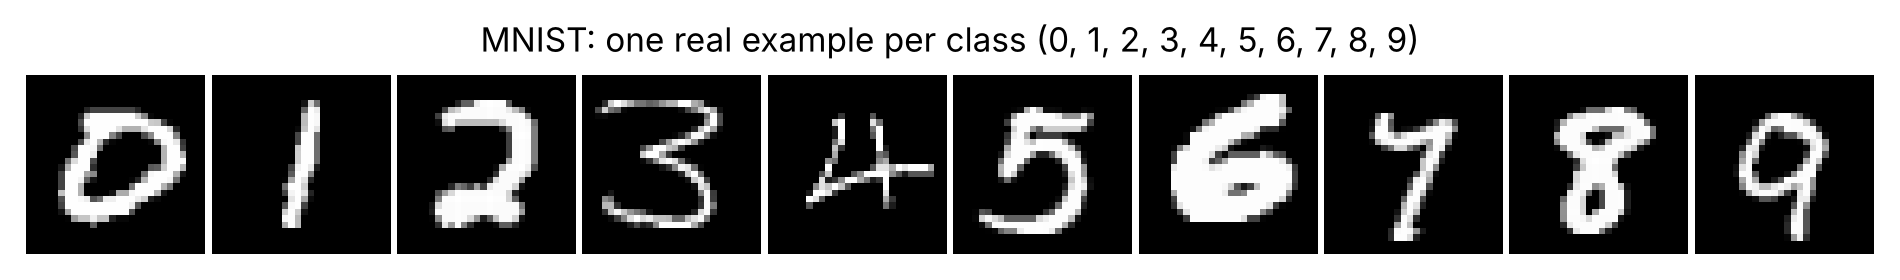

In [5]:
def to01(x):  return ((x.clamp(-1, 1) + 1) / 2).cpu()

def show_grid(x, nrow, title=None, name=None, figsize=(8, 8)):
    grid = make_grid(to01(x), nrow=nrow, padding=1, pad_value=1.0)
    plt.figure(figsize=figsize); plt.imshow(grid.permute(1, 2, 0)); plt.axis("off")
    if title: plt.title(title)
    if name: savefig(name)
    plt.show()

# one real example per class
firsts = [int(np.where(val_targets == c)[0][0]) for c in range(NUM_CLASSES)]
real_examples = torch.stack([ds_train_eval[val_idx[i]][0] for i in firsts])
show_grid(real_examples, 10, f"{DATASET}: one real example per class ({', '.join(NAMES)})", "real_examples", figsize=(12, 2))

## 2. Diffusion process (rubric c): schedule, forward noising

**Schedule.** Linear betas, `beta_1 = 1e-4` to `beta_T = 0.02` for T = 1000 (scaled proportionally if T is changed). With `alpha_t = 1 - beta_t` and `abar_t = prod_{s<=t} alpha_s`:

$$q(x_t \mid x_0) = \mathcal{N}\big(\sqrt{\bar\alpha_t}\,x_0,\ (1-\bar\alpha_t)\,I\big) \;\Rightarrow\; x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$$

The closed form comes from composing the one-step Gaussians: the two independent noise terms add in variance, `alpha_t(1 - alpha_{t-1}) + (1 - alpha_t) = 1 - alpha_t alpha_{t-1}`, and induction gives `1 - abar_t`. It lets training jump to any `t` in one operation instead of looping.

**Common bug:** schedule tensors have shape `[B]` but images are `[B, C, H, W]`; `extract()` reshapes to `[B, 1, 1, 1]` so broadcasting is correct.

In [6]:
betas = torch.linspace(1e-4 * 1000 / T_STEPS, 0.02 * 1000 / T_STEPS, T_STEPS, device=device)
alphas = 1.0 - betas
abar = torch.cumprod(alphas, dim=0)
abar_prev = F.pad(abar[:-1], (1, 0), value=1.0)
sqrt_abar = abar.sqrt()
sqrt_1m_abar = (1.0 - abar).sqrt()
posterior_var = betas * (1.0 - abar_prev) / (1.0 - abar)       # beta-tilde, used for reference

def extract(a, t):
    """a: [T] schedule tensor, t: [B] int timesteps -> [B,1,1,1] for broadcasting over images."""
    return a[t].view(-1, 1, 1, 1)

def q_sample(x0, t, noise=None):
    """FORWARD process: x_t = sqrt(abar_t) x0 + sqrt(1-abar_t) eps."""
    if noise is None:
        noise = torch.randn_like(x0)
    return extract(sqrt_abar, t) * x0 + extract(sqrt_1m_abar, t) * noise

print("abar_1 = %.5f (almost all signal) | abar_T = %.2e (almost pure noise)" % (abar[0].item(), abar[-1].item()))

abar_1 = 0.99990 (almost all signal) | abar_T = 4.04e-05 (almost pure noise)


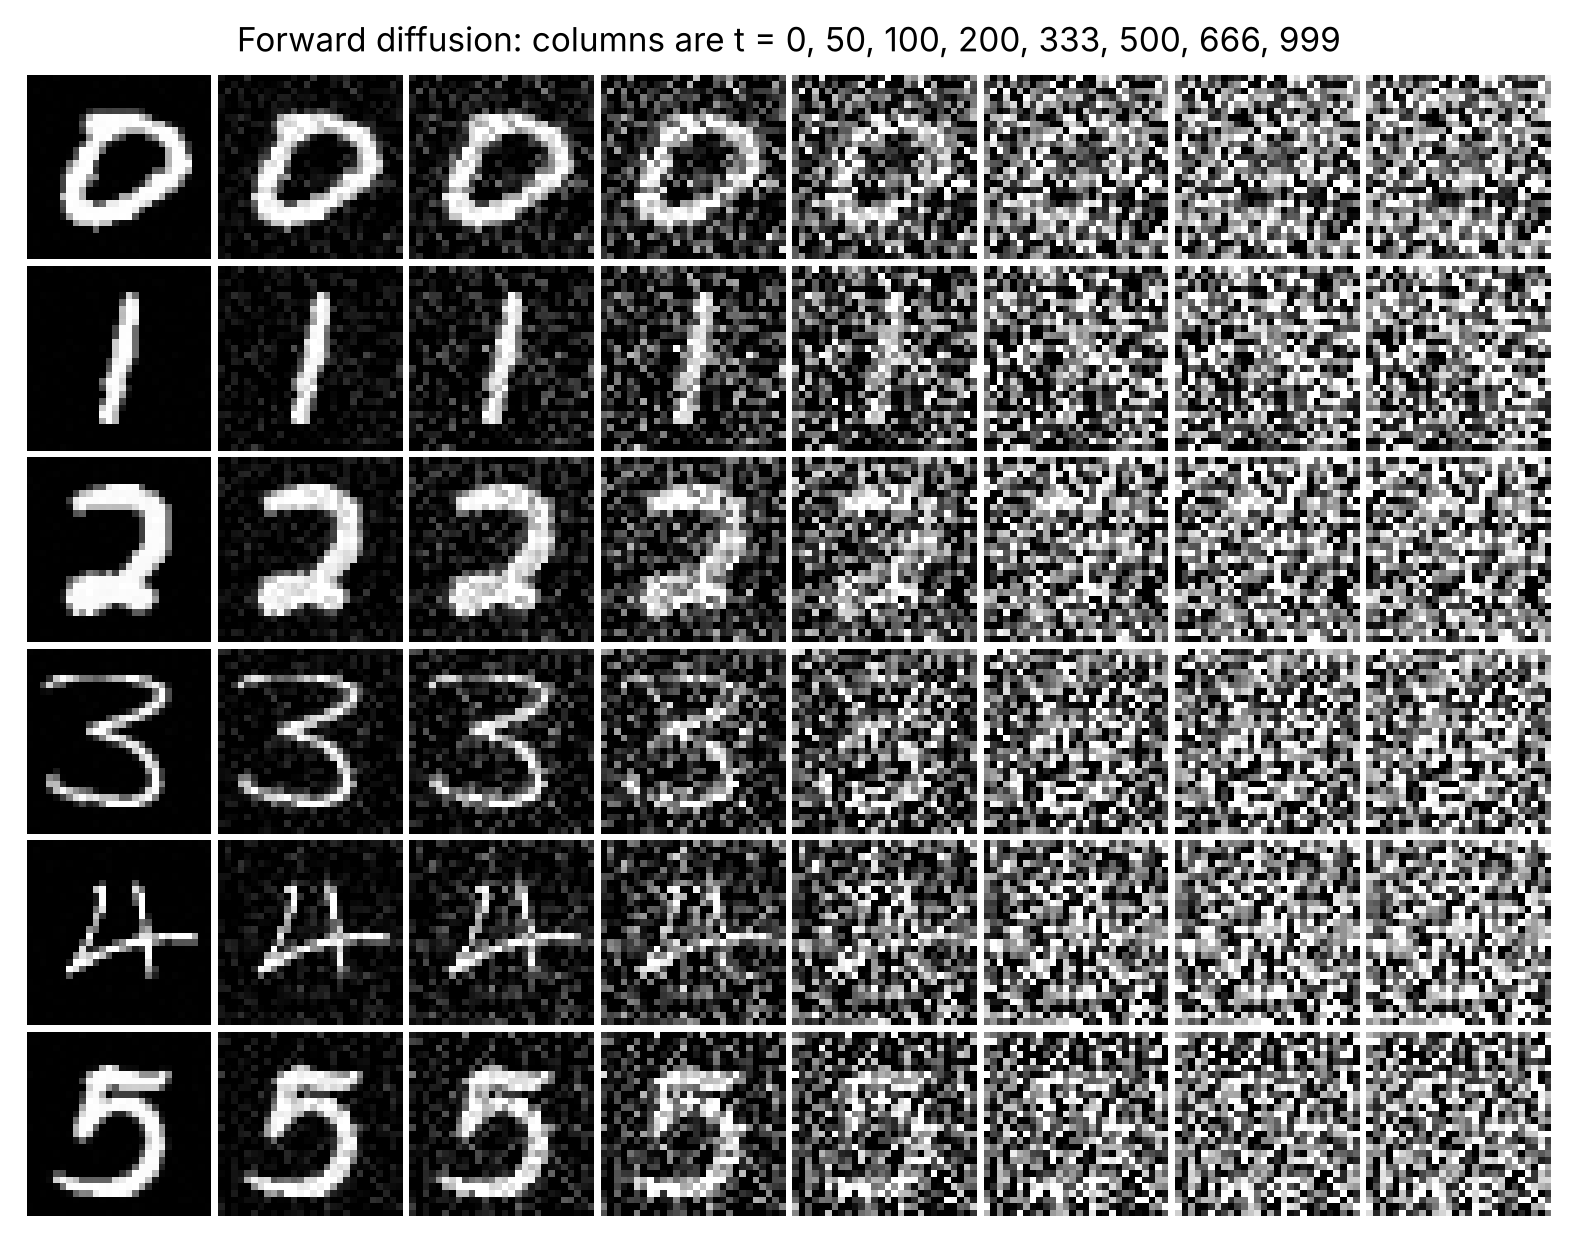

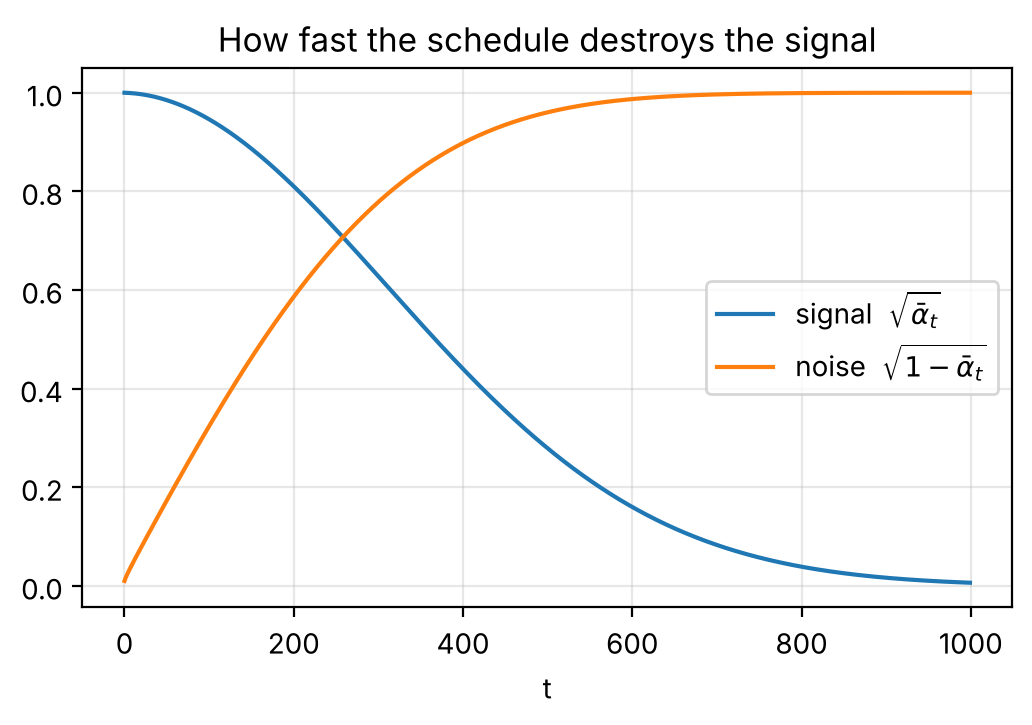

In [7]:
# Forward-process visualisation: rows = classes, columns = timesteps
show_ts = [0, T_STEPS // 20, T_STEPS // 10, T_STEPS // 5, T_STEPS // 3, T_STEPS // 2, 2 * T_STEPS // 3, T_STEPS - 1]
fixed_noise = torch.randn_like(real_examples[:6]).to(device)
rows = []
for i in range(6):
    for tt in show_ts:
        rows.append(q_sample(real_examples[i:i+1].to(device), torch.tensor([tt], device=device), fixed_noise[i:i+1])[0])
show_grid(torch.stack(rows), len(show_ts), "Forward diffusion: columns are t = " + ", ".join(map(str, show_ts)), "forward_process", figsize=(10, 7.5))

# Signal vs noise coefficients across the schedule
tt = torch.arange(T_STEPS).cpu()
plt.figure(figsize=(6, 3.5))
plt.plot(tt, sqrt_abar.cpu(), label=r"signal  $\sqrt{\bar\alpha_t}$")
plt.plot(tt, sqrt_1m_abar.cpu(), label=r"noise  $\sqrt{1-\bar\alpha_t}$")
plt.xlabel("t"); plt.legend(); plt.title("How fast the schedule destroys the signal"); plt.grid(alpha=.3)
savefig("schedule"); plt.show()

## 3. Model architecture (rubric b)

A small U-Net that predicts the noise `eps` from `(x_t, t, class)`.

* **`GELUConvBlock`**: Conv3x3 -> GroupNorm -> GELU. GroupNorm instead of BatchNorm because batch statistics are unreliable with the wildly different noise levels inside one batch.
* **Time embedding**: sinusoidal embedding of `t` -> MLP. The same weights must behave differently at t=900 (denoise heavy noise, coarse structure) and t=20 (clean up fine detail), so the network is told the noise level.
* **Class conditioning**: `nn.Embedding(num_classes + 1, emb_dim)`; the extra index is a "null" label used for classifier-free guidance (section 9). The class embedding is **added** to the time embedding, and the sum conditions every residual block through FiLM (a learned per-channel scale and shift: `h = h * (1 + scale) + shift`).
* **Skip connections**: the decoder concatenates the encoder feature map of the same resolution. The output is a pixel-accurate noise map, and downsampling destroys the spatial detail needed for that. Skips hand it back, and also give gradients a short path.
* A single self-attention layer at the lowest resolution (7x7 or 8x8) lets distant strokes coordinate.

In [8]:
class GELUConvBlock(nn.Module):
    """Conv3x3 -> GroupNorm -> GELU"""
    def __init__(self, in_ch, out_ch, groups=8):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.GroupNorm(groups, out_ch),
            nn.GELU(),
        )
    def forward(self, x):
        return self.block(x)


class ResBlock(nn.Module):
    """Two GELUConvBlocks with FiLM conditioning from the (time + class) embedding, plus a residual path."""
    def __init__(self, in_ch, out_ch, emb_dim):
        super().__init__()
        self.conv1 = GELUConvBlock(in_ch, out_ch)
        self.film = nn.Linear(emb_dim, 2 * out_ch)
        self.conv2 = GELUConvBlock(out_ch, out_ch)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
    def forward(self, x, emb):
        h = self.conv1(x)
        scale, shift = self.film(emb)[:, :, None, None].chunk(2, dim=1)
        h = h * (1 + scale) + shift
        h = self.conv2(h)
        return h + self.skip(x)


class DownBlock(nn.Module):
    """ResBlock, then stride-2 conv. Returns the pre-downsample features (for the skip) and the downsampled map."""
    def __init__(self, in_ch, out_ch, emb_dim):
        super().__init__()
        self.res = ResBlock(in_ch, out_ch, emb_dim)
        self.down = nn.Conv2d(out_ch, out_ch, 3, stride=2, padding=1)
    def forward(self, x, emb):
        skip = self.res(x, emb)
        return skip, self.down(skip)


class UpBlock(nn.Module):
    """Upsample x2, concatenate the encoder skip, then ResBlock."""
    def __init__(self, in_ch, skip_ch, out_ch, emb_dim):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, in_ch, 4, stride=2, padding=1)    # exactly doubles H and W
        self.res = ResBlock(in_ch + skip_ch, out_ch, emb_dim)
    def forward(self, x, skip, emb):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)            # skip connection
        return self.res(x, emb)


class SelfAttention(nn.Module):
    def __init__(self, ch, heads=4):
        super().__init__()
        self.norm = nn.GroupNorm(8, ch)
        self.attn = nn.MultiheadAttention(ch, heads, batch_first=True)
    def forward(self, x):
        B, C, H, W = x.shape
        h = self.norm(x).flatten(2).transpose(1, 2)               # [B, HW, C]
        h, _ = self.attn(h, h, h, need_weights=False)
        return x + h.transpose(1, 2).reshape(B, C, H, W)


def timestep_embedding(t, dim):
    """Sinusoidal embedding, as in Transformers: sin/cos at geometrically spaced frequencies."""
    half = dim // 2
    freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([args.sin(), args.cos()], dim=-1)


class UNet(nn.Module):
    def __init__(self, in_ch=1, base=64, num_classes=10, emb_dim=256):
        super().__init__()
        C = base
        self.emb_dim = emb_dim
        self.num_classes = num_classes
        self.time_mlp = nn.Sequential(nn.Linear(emb_dim, emb_dim), nn.GELU(), nn.Linear(emb_dim, emb_dim))
        self.class_emb = nn.Embedding(num_classes + 1, emb_dim)       # last index = "no class" (null token)

        self.init_conv = nn.Conv2d(in_ch, C, 3, padding=1)
        self.down1 = DownBlock(C, C, emb_dim)             # H    -> H/2
        self.down2 = DownBlock(C, 2 * C, emb_dim)         # H/2  -> H/4
        self.mid1 = ResBlock(2 * C, 2 * C, emb_dim)
        self.attn = SelfAttention(2 * C)
        self.mid2 = ResBlock(2 * C, 2 * C, emb_dim)
        self.up1 = UpBlock(2 * C, 2 * C, C, emb_dim)      # H/4 -> H/2, skip from down2
        self.up2 = UpBlock(C, C, C, emb_dim)              # H/2 -> H,   skip from down1
        self.out = nn.Sequential(nn.GroupNorm(8, C), nn.GELU(), nn.Conv2d(C, in_ch, 3, padding=1))

    def forward(self, x, t, y):
        emb = self.time_mlp(timestep_embedding(t, self.emb_dim)) + self.class_emb(y)   # time + class conditioning
        h = self.init_conv(x)
        s1, h = self.down1(h, emb)
        s2, h = self.down2(h, emb)
        h = self.mid1(h, emb); h = self.attn(h); h = self.mid2(h, emb)
        h = self.up1(h, s2, emb)
        h = self.up2(h, s1, emb)
        return self.out(h)


model = UNet(CH, BASE, NUM_CLASSES).to(device)
print("parameters: %.2f M" % (sum(p.numel() for p in model.parameters()) / 1e6))
# shape test: output must equal input shape
with torch.no_grad():
    _x = torch.randn(4, CH, SIZE, SIZE, device=device)
    _o = model(_x, torch.randint(0, T_STEPS, (4,), device=device), torch.randint(0, NUM_CLASSES, (4,), device=device))
assert _o.shape == _x.shape, (_o.shape, _x.shape)
print("shape check OK:", tuple(_o.shape))
RESULTS["parameters_M"] = round(sum(p.numel() for p in model.parameters()) / 1e6, 3)

parameters: 0.73 M
shape check OK: (4, 1, 28, 28)


## 4. Reverse process and training step (rubric c)

**Training objective.** Pick a random `t`, noise a clean image to get `x_t`, ask the network for the noise that was added, and minimise MSE:

$$L = \mathbb{E}_{x_0,\,t,\,\epsilon}\,\big\|\epsilon - \epsilon_\theta(x_t, t, c)\big\|^2$$

**Why predict noise?** The true reverse-step mean is

$$\tilde\mu_t = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon\Big)$$

after substituting $x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\epsilon)/\sqrt{\bar\alpha_t}$ into the posterior mean. So the single unknown is $\epsilon$, which the network supplies.

**Reverse step.** `x_{t-1} = mean + sqrt(beta_t) * z`, with `z ~ N(0, I)` for `t > 1` and **no noise on the very last step** (otherwise every sample carries visible grain).

**Class-label dropout.** With probability 0.1 the label is replaced by the null token. One network then learns both the conditional and unconditional noise predictor, which is what classifier-free guidance (section 9) needs. At guidance scale `w = 1` sampling is purely conditional.

**Stability tools:** gradient clipping at 1.0 (and the pre-clip norm is logged so exploding gradients are visible), AdamW, and an exponential moving average (EMA) of the weights used for sampling.

In [9]:
NULL = NUM_CLASSES   # index of the "no class" token

def train_step(model, opt, x0, y, p_uncond=0.1):
    """One optimisation step. Returns (loss, pre-clip grad norm)."""
    x0, y = x0.to(device, non_blocking=True), y.to(device, non_blocking=True)
    t = torch.randint(0, T_STEPS, (x0.size(0),), device=device)           # random timestep per image
    noise = torch.randn_like(x0)
    xt = q_sample(x0, t, noise)                                           # forward process
    drop = torch.rand(y.size(0), device=device) < p_uncond                # classifier-free-guidance label dropout
    y_in = torch.where(drop, torch.full_like(y, NULL), y)
    loss = F.mse_loss(model(xt, t, y_in), noise)                          # predict the noise
    opt.zero_grad(set_to_none=True)
    loss.backward()
    gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    return loss.item(), float(gnorm)


@torch.no_grad()
def predict_eps(net, x, t, y, w):
    """Conditional noise prediction; for w != 1 apply classifier-free guidance: eps_u + w (eps_c - eps_u)."""
    if w == 1.0:
        return net(x, t, y)
    y_null = torch.full_like(y, NULL)
    ec, eu = net(torch.cat([x, x]), torch.cat([t, t]), torch.cat([y, y_null])).chunk(2)
    return eu + w * (ec - eu)


@torch.no_grad()
def p_sample(net, x, i, y, w=1.0, gen=None):
    """REVERSE process, one step x_t -> x_{t-1}. `i` is the 0-based index of t. Also returns the x0 estimate."""
    t = torch.full((x.size(0),), i, device=device, dtype=torch.long)
    eps = predict_eps(net, x, t, y, w)
    mean = (x - betas[i] / sqrt_1m_abar[i] * eps) / alphas[i].sqrt()
    x0_hat = ((x - sqrt_1m_abar[i] * eps) / sqrt_abar[i]).clamp(-1, 1)
    if i > 0:
        x_prev = mean + betas[i].sqrt() * torch.randn(x.shape, device=device, generator=gen)
    else:
        x_prev = mean                                                      # no noise on the final step
    return x_prev, x0_hat


@torch.no_grad()
def ddpm_sample(net, labels, w=1.0, record=None, seed=None):
    """Full ancestral sampling from pure noise. `record`: set of step indices whose (x_t, x0_hat) to keep."""
    net.eval()
    gen = torch.Generator(device=device).manual_seed(seed) if seed is not None else None
    labels = labels.to(device)
    x = torch.randn((len(labels), CH, SIZE, SIZE), device=device, generator=gen)
    rec = {}
    for i in reversed(range(T_STEPS)):
        x_new, x0_hat = p_sample(net, x, i, labels, w, gen)
        if record is not None and i in record:
            rec[i] = (x.cpu(), x0_hat.cpu())
        x = x_new
    x = x.clamp(-1, 1)
    return (x, rec) if record is not None else x


class EMA:
    """Exponential moving average of weights. Sampling from the EMA copy is noticeably cleaner than from raw weights."""
    def __init__(self, model, decay=0.995):
        self.model = copy.deepcopy(model).eval()
        for p in self.model.parameters(): p.requires_grad_(False)
        self.decay, self.n = decay, 0
    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))                  # warm-up so early EMA is not dominated by init
        for pe, p in zip(self.model.parameters(), model.parameters()):
            pe.mul_(d).add_(p.detach(), alpha=1 - d)


@torch.no_grad()
def val_loss(net):
    """Validation noise-prediction MSE, with fixed t/noise draws so values are comparable across epochs."""
    net.eval(); g = torch.Generator(device=device).manual_seed(0); tot = n = 0
    for x, y in val_loader:
        x, y = x.to(device), y.to(device)
        t = torch.randint(0, T_STEPS, (len(x),), device=device, generator=g)
        noise = torch.randn(x.shape, device=device, generator=g)
        tot += F.mse_loss(net(q_sample(x, t, noise), t, y), noise, reduction="sum").item(); n += noise.numel()
    return tot / n

# quick sanity check before spending GPU time: a single step must run and give a finite loss
_opt = torch.optim.AdamW(copy.deepcopy(model).parameters(), lr=LR)
print("sanity train_step:", train_step(copy.deepcopy(model), _opt, *next(iter(train_loader)))) 

sanity train_step: (1.1445724964141846, 4.669574737548828)


## 5. Training (rubric d)

Checkpoints are written after every epoch, and `RESUME = True` continues from the last one, so a Colab disconnect does not cost the run. Sample snapshots (same labels, same starting noise) are taken at several epochs so the progression of image quality can be shown in the report.

For Colab, if you want checkpoints to survive a runtime reset, mount Google Drive and point `CKPT_DIR` at it:
```python
# from google.colab import drive; drive.mount('/content/drive')
# CKPT_DIR = '/content/drive/MyDrive/diffusion_ckpts'
```

In [10]:
CKPT_DIR = "checkpoints"; os.makedirs(CKPT_DIR, exist_ok=True)
tag = DATASET + ("_smoke" if SMOKE_TEST else "")
ckpt_path = f"{CKPT_DIR}/{tag}_last.pt"

model = UNet(CH, BASE, NUM_CLASSES).to(device)
ema = EMA(model, 0.995)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.0)
history = dict(train=[], val=[], gnorm=[], seconds=[])
snaps, start_epoch = {}, 0
snap_labels = torch.arange(NUM_CLASSES)

if RESUME and os.path.exists(ckpt_path):
    ck = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(ck["model"]); ema.model.load_state_dict(ck["ema"]); opt.load_state_dict(ck["opt"])
    history, snaps, start_epoch, ema.n = ck["history"], ck["snaps"], ck["epoch"], ck["ema_n"]
    print(f"resumed from epoch {start_epoch}")

for epoch in range(start_epoch + 1, EPOCHS + 1):
    model.train(); t0 = time.time(); tl, gn = [], []
    for x, y in train_loader:
        l, g_ = train_step(model, opt, x, y)
        ema.update(model); tl.append(l); gn.append(g_)
    vl = val_loss(model)
    history["train"].append(float(np.mean(tl))); history["val"].append(vl)
    history["gnorm"].append(float(np.mean(gn))); history["seconds"].append(time.time() - t0)
    if epoch in SNAP_EPOCHS:
        snaps[epoch] = to01(ddpm_sample(ema.model, snap_labels, w=1.0, seed=123))
    torch.save(dict(model=model.state_dict(), ema=ema.model.state_dict(), opt=opt.state_dict(), history=history,
                    snaps=snaps, epoch=epoch, ema_n=ema.n), ckpt_path)
    print(f"epoch {epoch:3d}/{EPOCHS} | train {history['train'][-1]:.4f} | val {vl:.4f} | grad-norm {history['gnorm'][-1]:.2f} | {history['seconds'][-1]:.0f}s")

torch.save(ema.model.state_dict(), f"{CKPT_DIR}/{tag}_ema_final.pt")
RESULTS.update(final_train_loss=history["train"][-1], final_val_loss=history["val"][-1],
               train_minutes=round(sum(history["seconds"]) / 60, 1))

epoch   1/10 | train 0.0817 | val 0.0371 | grad-norm 0.44 | 180s


epoch   2/10 | train 0.0342 | val 0.0312 | grad-norm 0.34 | 188s


epoch   3/10 | train 0.0302 | val 0.0285 | grad-norm 0.33 | 180s


epoch   4/10 | train 0.0280 | val 0.0271 | grad-norm 0.31 | 183s


epoch   5/10 | train 0.0275 | val 0.0264 | grad-norm 0.31 | 186s


epoch   6/10 | train 0.0264 | val 0.0255 | grad-norm 0.28 | 217s


epoch   7/10 | train 0.0258 | val 0.0250 | grad-norm 0.27 | 215s


epoch   8/10 | train 0.0254 | val 0.0246 | grad-norm 0.23 | 209s


epoch   9/10 | train 0.0247 | val 0.0249 | grad-norm 0.25 | 221s


epoch  10/10 | train 0.0247 | val 0.0239 | grad-norm 0.24 | 217s


## 6. Training diagnostics

What the plots mean: the loss is the per-pixel MSE between true and predicted noise. It falls fast and then flattens, because a large part of it is irreducible. At high `t` the target noise is almost fully recoverable from `x_t`, but at low `t` the noise is hidden in tiny differences and cannot be separated from image detail. A flat loss therefore does **not** mean sample quality has stopped improving, which is why the snapshots below matter more than the curve.

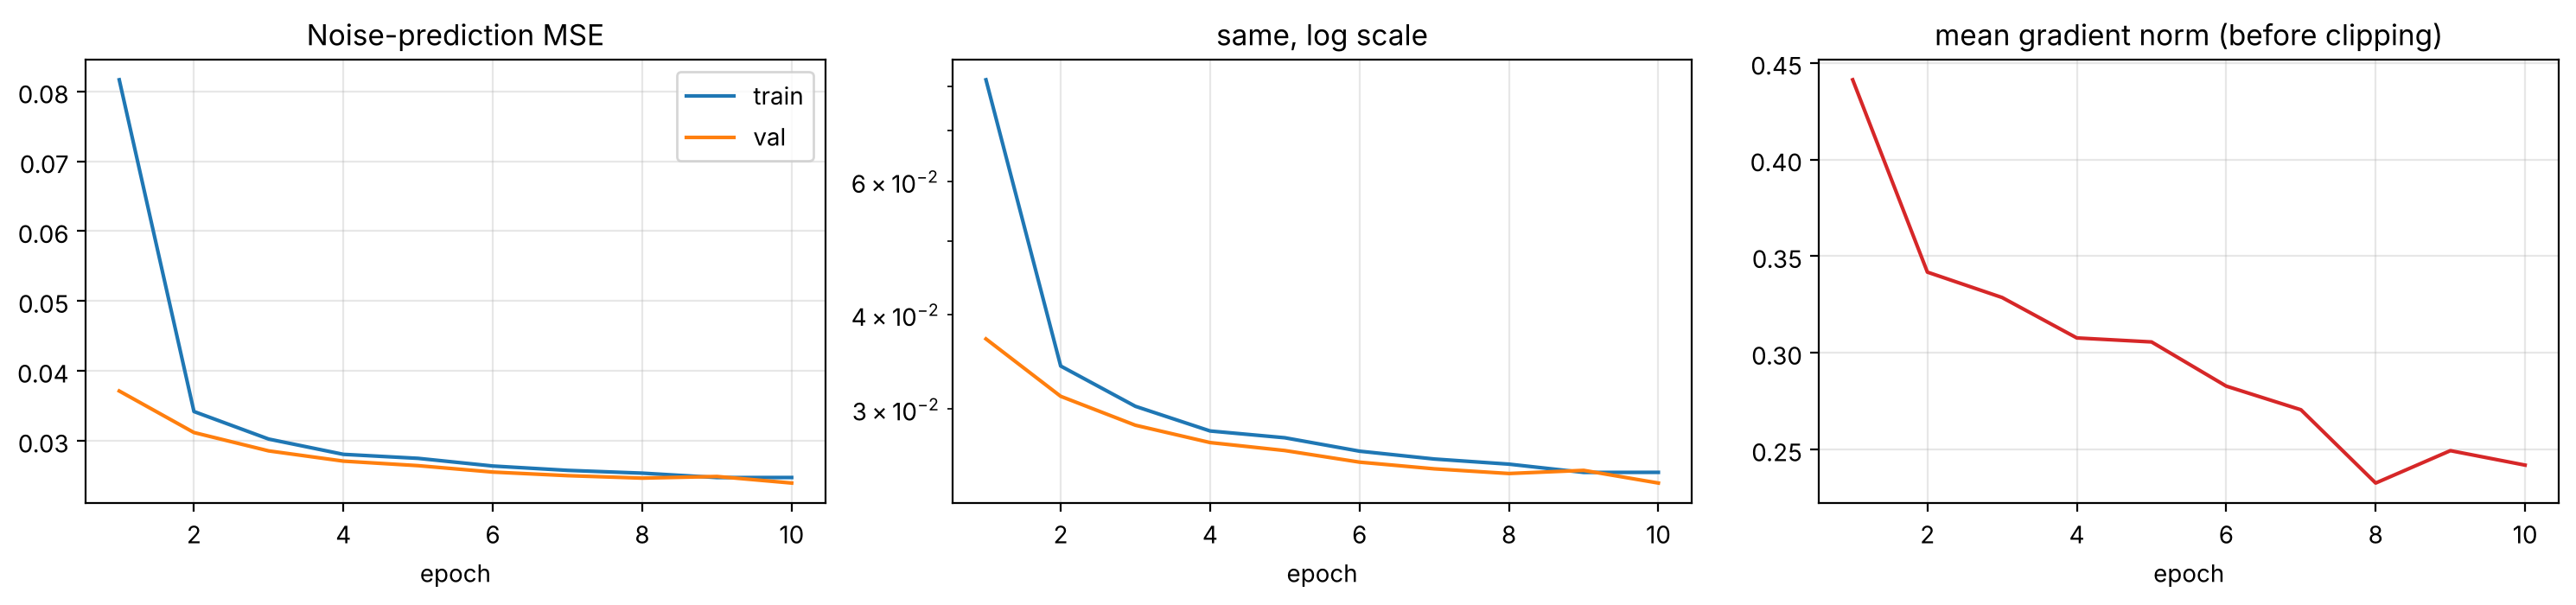

gradient norm range: 0.23 to 0.44  (clip threshold 1.0; huge or NaN values would signal instability)


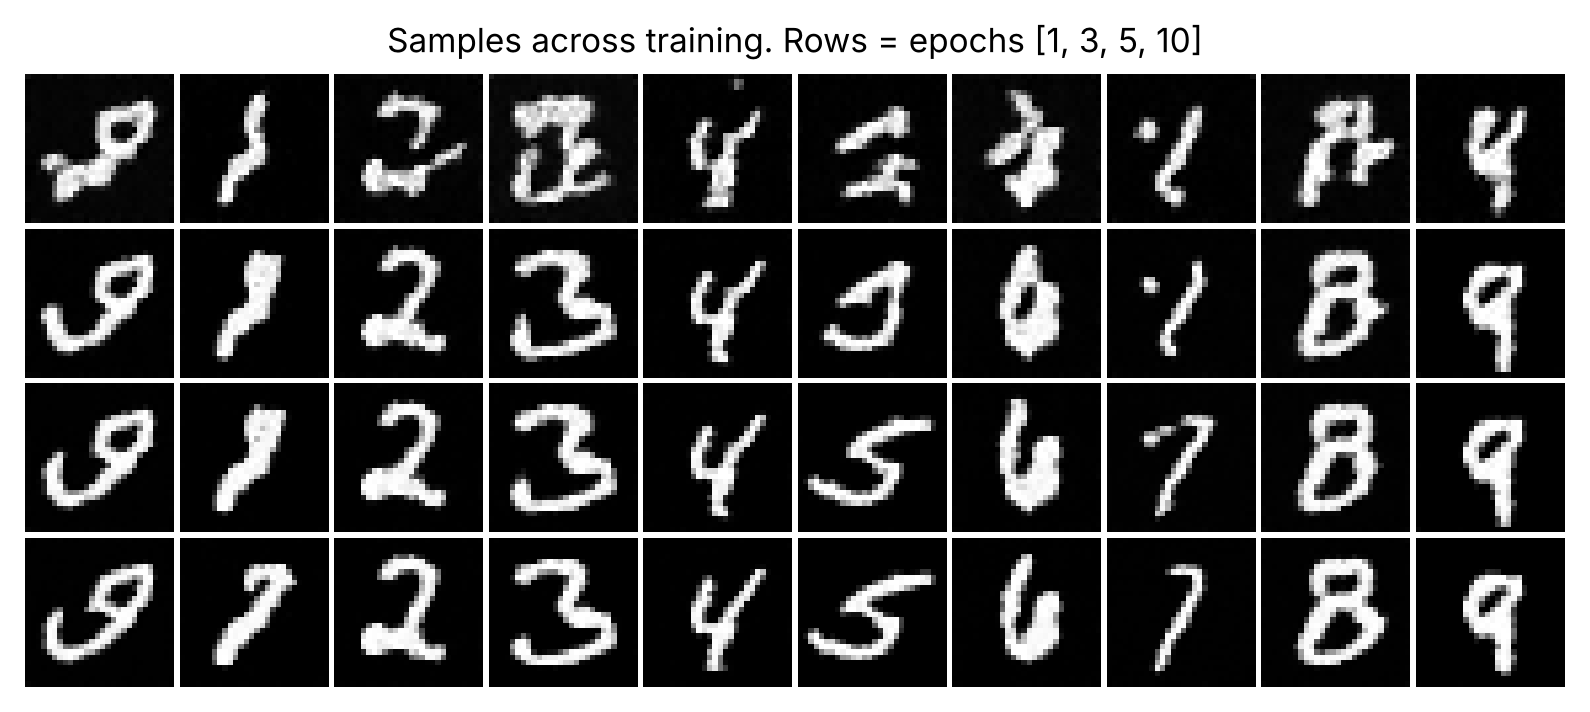

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ep = np.arange(1, len(history["train"]) + 1)
ax[0].plot(ep, history["train"], label="train"); ax[0].plot(ep, history["val"], label="val")
ax[0].set_title("Noise-prediction MSE"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ep, history["train"], label="train"); ax[1].plot(ep, history["val"], label="val")
ax[1].set_yscale("log"); ax[1].set_title("same, log scale"); ax[1].set_xlabel("epoch"); ax[1].grid(alpha=.3)
ax[2].plot(ep, history["gnorm"], color="C3"); ax[2].set_title("mean gradient norm (before clipping)")
ax[2].set_xlabel("epoch"); ax[2].grid(alpha=.3)
plt.tight_layout(); savefig("training_curves"); plt.show()
print("gradient norm range: %.2f to %.2f  (clip threshold 1.0; huge or NaN values would signal instability)" % (min(history["gnorm"]), max(history["gnorm"])))

# Sample quality across training: rows = epochs, columns = classes 0..9, same labels and starting noise each time
ep_list = sorted(snaps)
show_grid(torch.cat([snaps[e] * 2 - 1 for e in ep_list]), NUM_CLASSES,   # snaps are stored in [0,1]; show_grid expects [-1,1]
          "Samples across training. Rows = epochs " + str(ep_list), "training_progress", figsize=(10, 1.1 * len(ep_list) + 1))

## 7. Sampling and quantitative evaluation (rubric d)

### 7a. Samples for every class, and the step-by-step generation process

sampled 100 images with 1000 DDPM steps in 99.7s


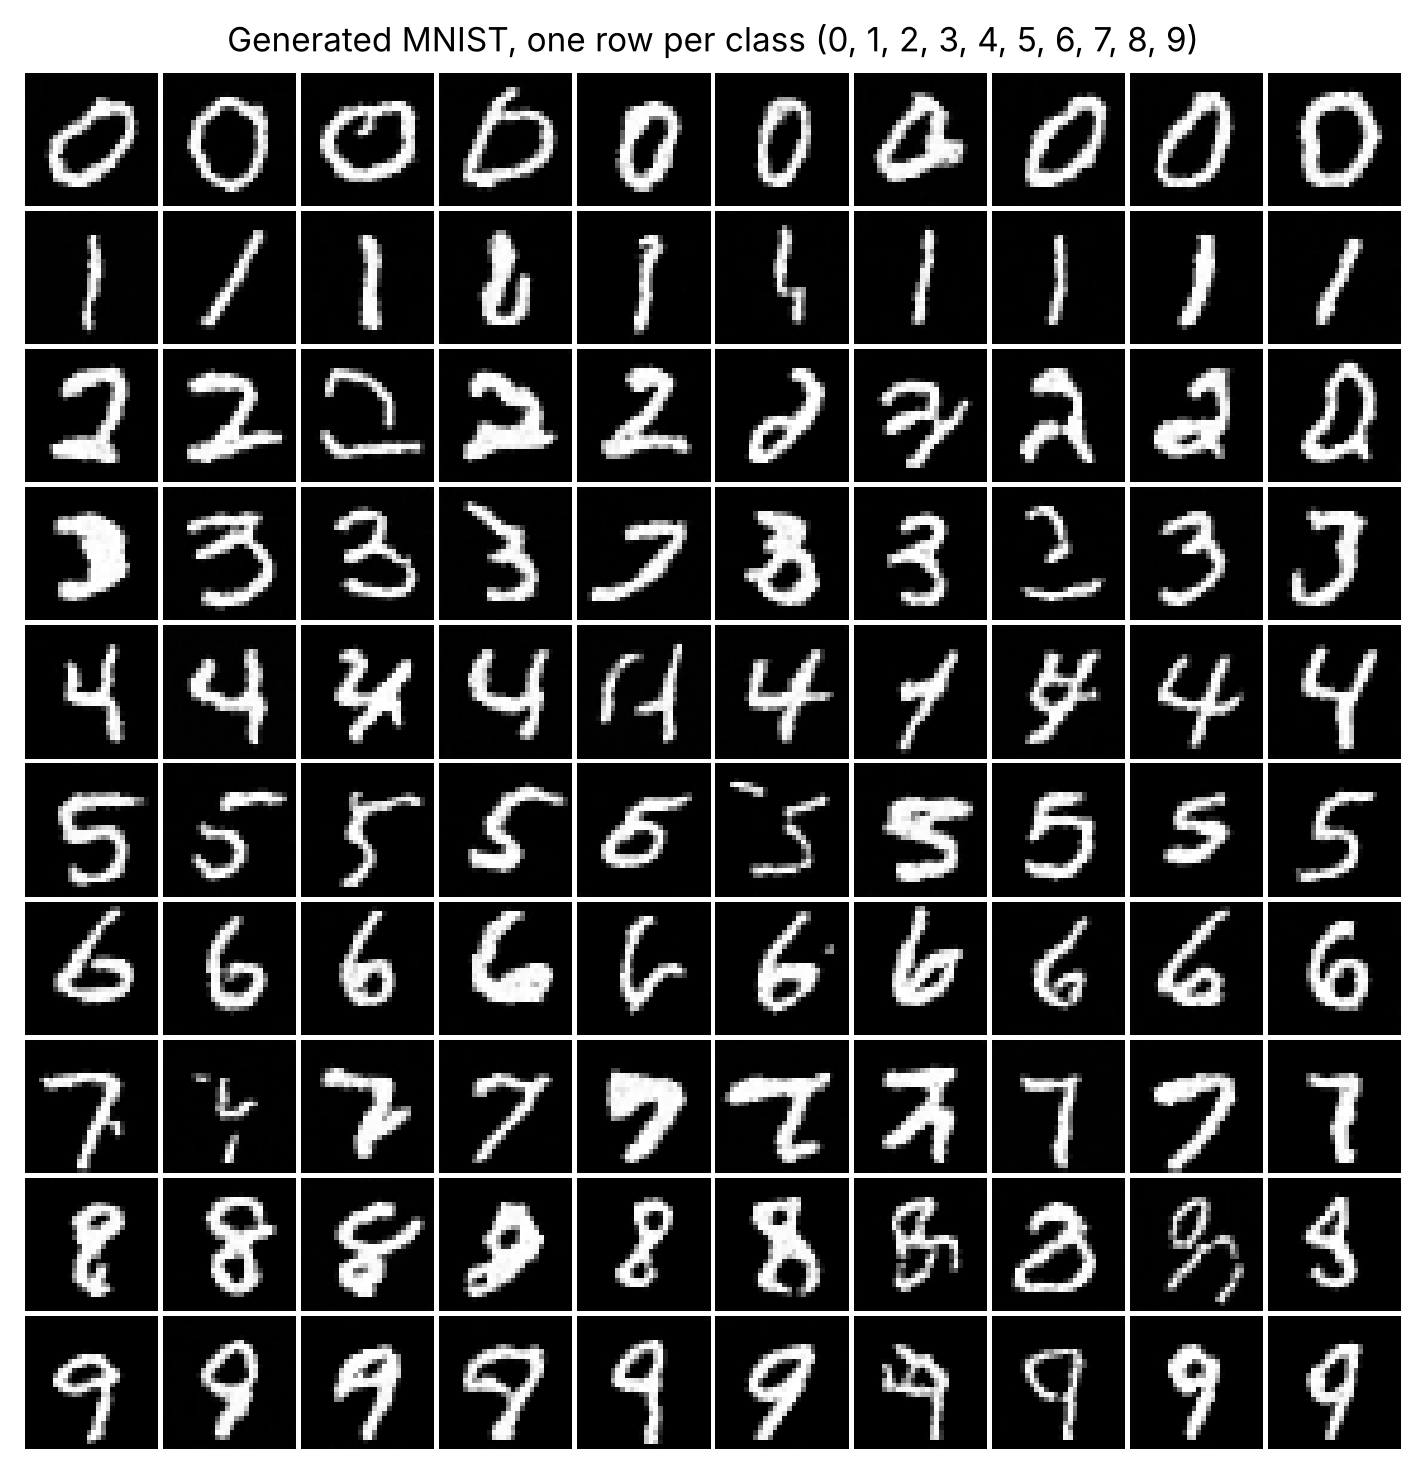

In [12]:
net = ema.model.eval()
gen_labels = torch.arange(NUM_CLASSES).repeat_interleave(N_PER_CLASS)
rec_ts = sorted(set(np.linspace(T_STEPS - 1, 0, 11).astype(int).tolist()), reverse=True)
t0 = time.time()
gen_imgs, rec = ddpm_sample(net, gen_labels, w=1.0, record=set(rec_ts), seed=2024)
RESULTS["ddpm_sample_seconds"] = round(time.time() - t0, 1)
print(f"sampled {len(gen_imgs)} images with {T_STEPS} DDPM steps in {RESULTS['ddpm_sample_seconds']}s")

# all classes: each row = one class
show_grid(gen_imgs[::max(1, N_PER_CLASS // 10)][: NUM_CLASSES * 10] if N_PER_CLASS >= 10 else gen_imgs, 10 if N_PER_CLASS >= 10 else N_PER_CLASS,
          f"Generated {DATASET}, one row per class ({', '.join(NAMES)})", "samples_all_classes", figsize=(9, 9))

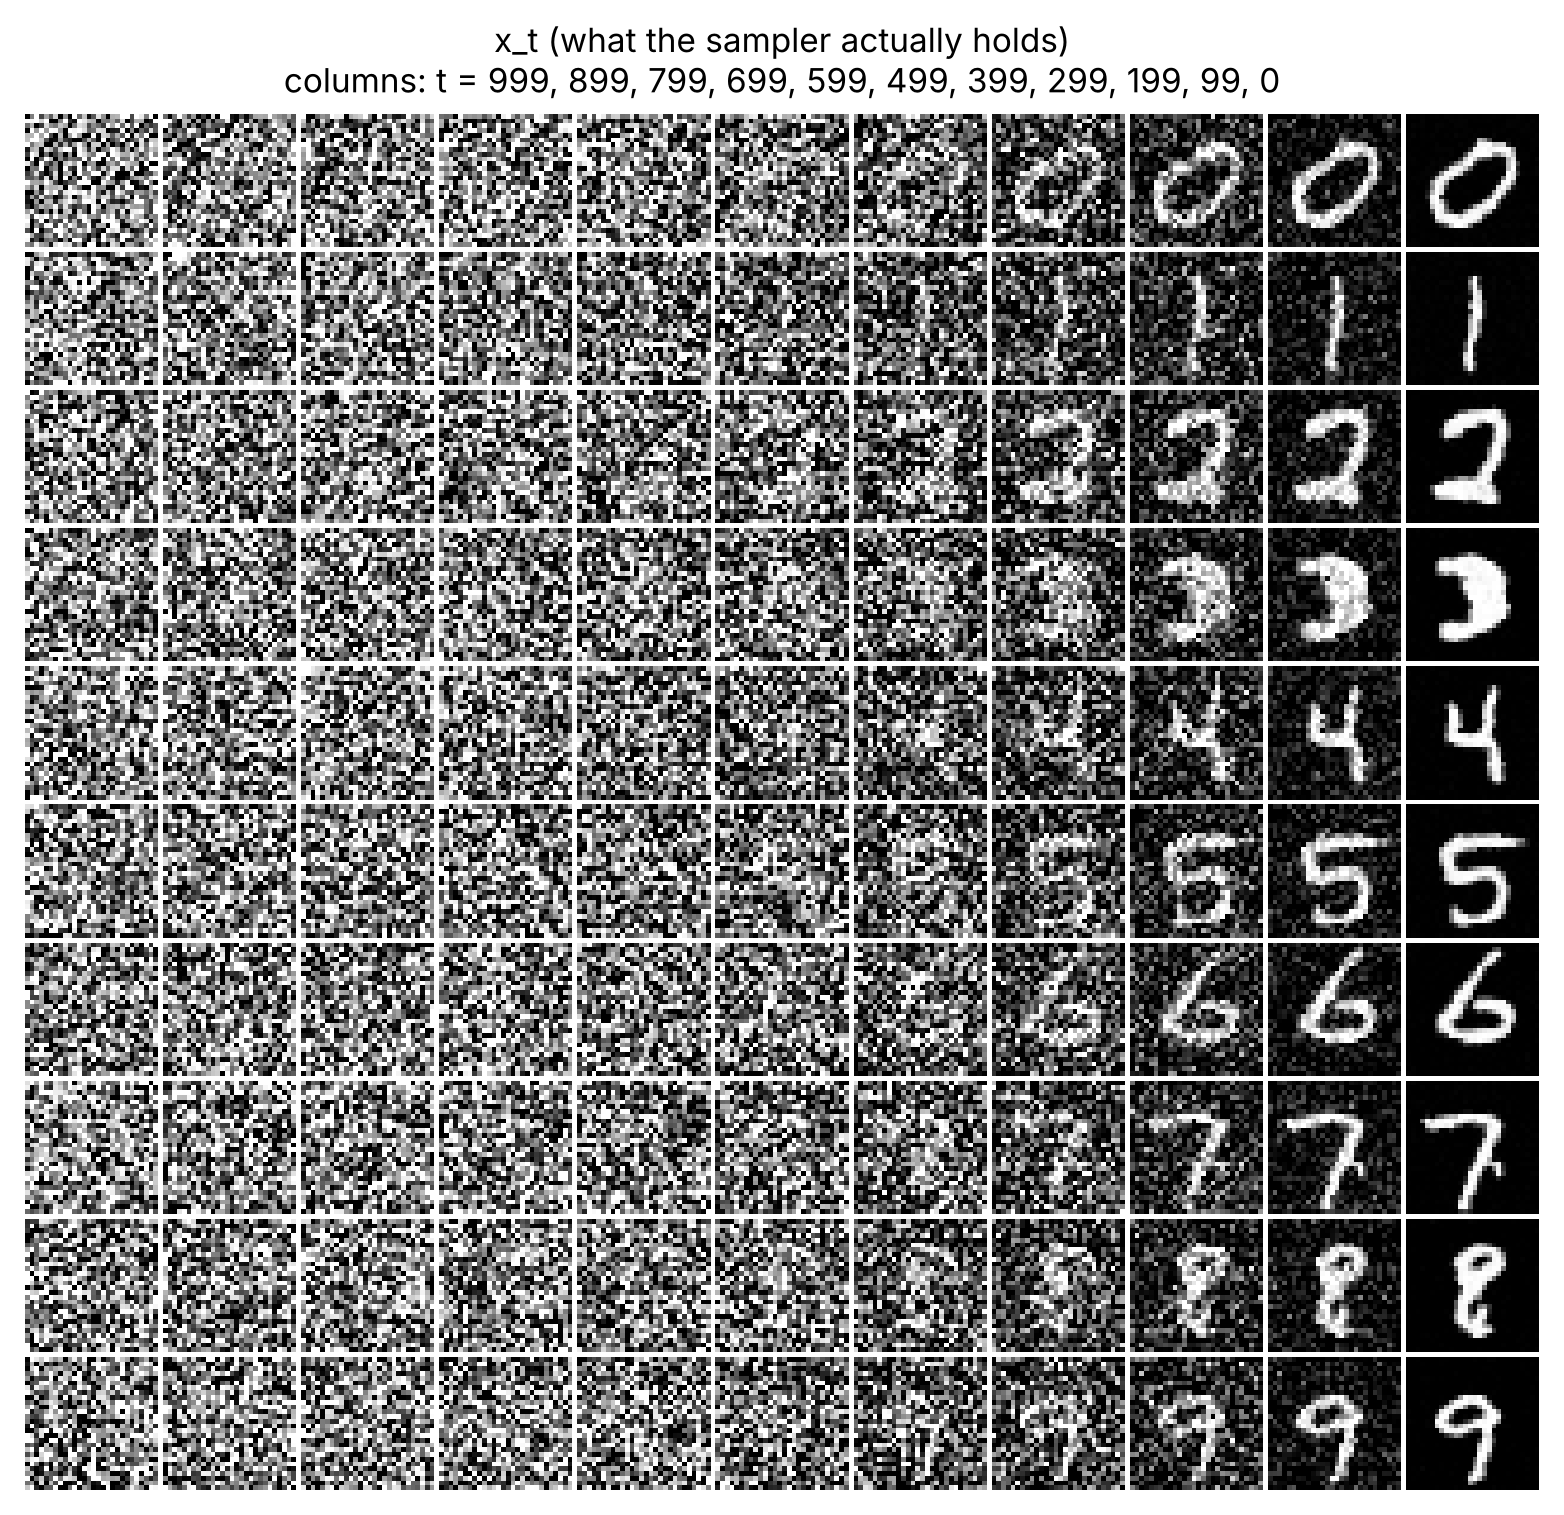

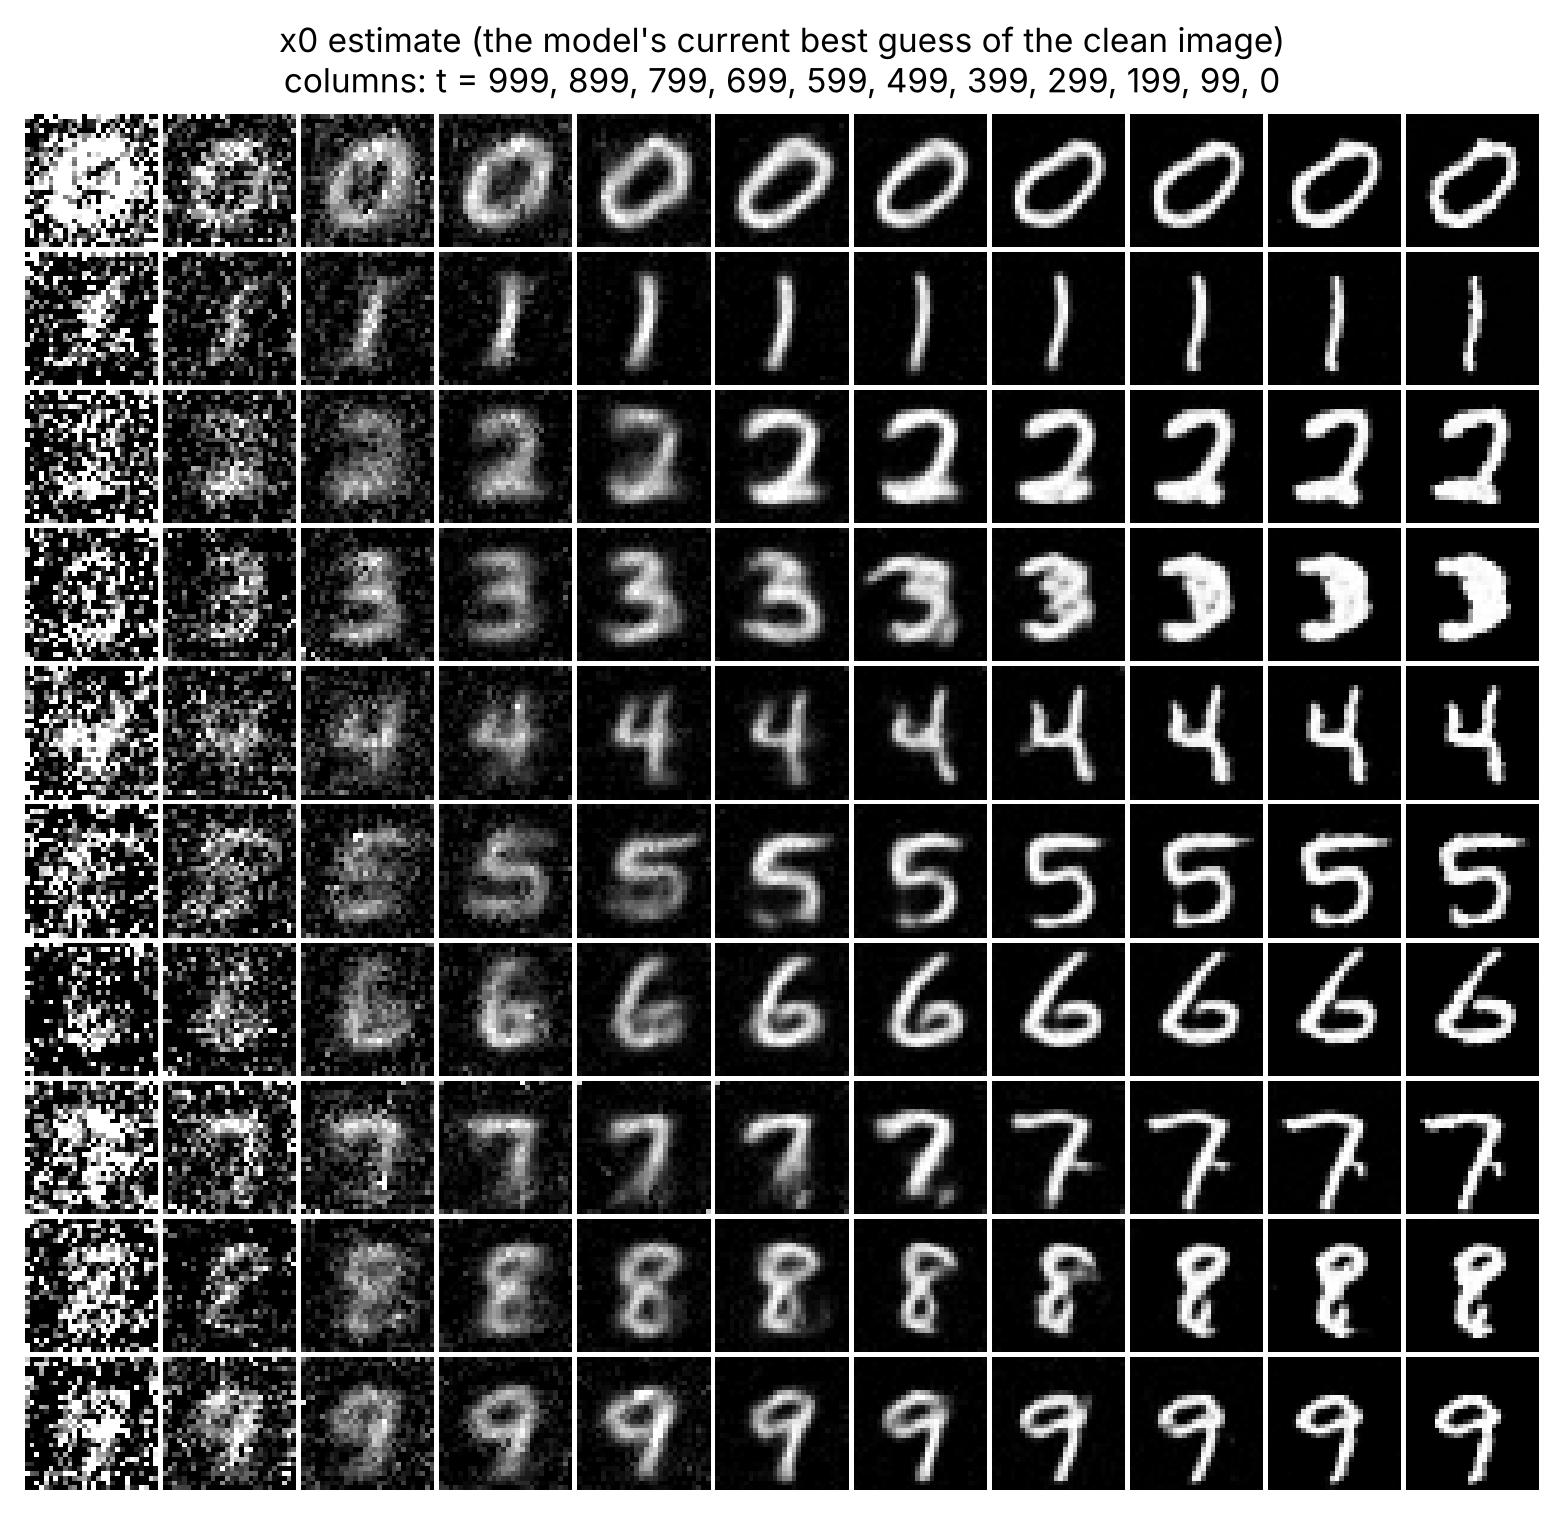

In [13]:
# Step-by-step generation: one sample per class. Rows = classes, columns = timesteps (noisy -> clean), last column = final.
first_idx = [c * N_PER_CLASS for c in range(NUM_CLASSES)]
cols = rec_ts
xt_rows = [rec[tt][0][i] for i in first_idx for tt in cols]
x0_rows = [rec[tt][1][i] for i in first_idx for tt in cols]
for i_, (title, rows_, nm) in enumerate([("x_t (what the sampler actually holds)", xt_rows, "trajectory_xt"),
                                         ("x0 estimate (the model's current best guess of the clean image)", x0_rows, "trajectory_x0hat")]):
    show_grid(torch.stack(rows_), len(cols), f"{title}\ncolumns: t = " + ", ".join(map(str, cols)), nm, figsize=(10, 9))

### 7b. An independent judge: a small classifier trained on real data
CLIP is a weak judge on 28x28 digits (it was not trained on tiny handwritten glyphs), so I also train a small CNN on the real training set and use it to measure whether generated samples are the *class they were asked to be*. It also gives a measured answer to "at what point do images become recognizable".

Caveat for the report: the classifier sees `x_t` (noisy images it never trained on) and `x0_hat` (blurry averages early on), so these curves show when *class identity* becomes detectable to this classifier, not when a person would call the image good.

classifier accuracy on REAL test images: 0.9918
classifier accuracy on GENERATED samples (intended class recovered): 0.9500
             0: 1.00
             1: 1.00
             2: 0.90
             3: 0.80
             4: 1.00
             5: 0.90
             6: 1.00
             7: 0.90
             8: 1.00
             9: 1.00


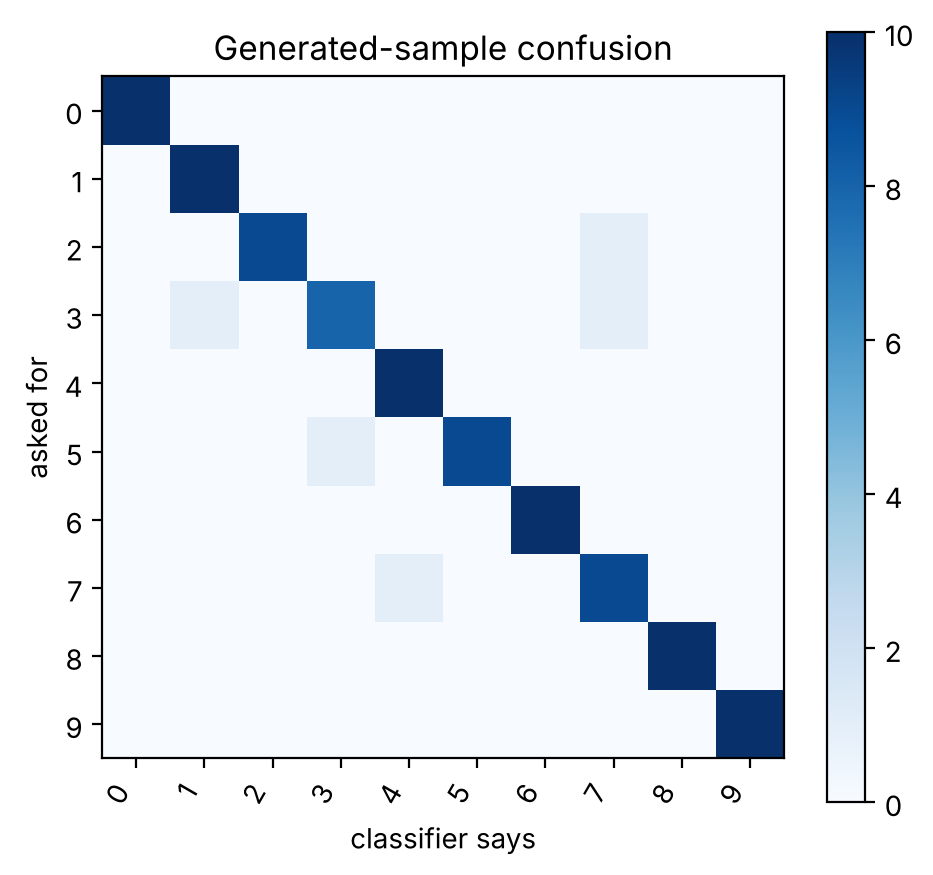

In [14]:
class SmallCNN(nn.Module):
    def __init__(self, ch, size):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(ch, 32, 3, padding=1), nn.GELU(), nn.MaxPool2d(2),
                               nn.Conv2d(32, 64, 3, padding=1), nn.GELU(), nn.MaxPool2d(2), nn.Flatten(),
                               nn.Linear(64 * (size // 4) ** 2, 128), nn.GELU(), nn.Linear(128, 10))
    def forward(self, x): return self.f(x)

clf = SmallCNN(CH, SIZE).to(device)
opt_c = torch.optim.Adam(clf.parameters(), 1e-3)
for e in range(1 if SMOKE_TEST else 3):
    clf.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(clf(x), y); opt_c.zero_grad(); loss.backward(); opt_c.step()
clf.eval()

@torch.no_grad()
def clf_probs(x):
    return torch.cat([clf(x[i:i + 512].to(device)).softmax(-1).cpu() for i in range(0, len(x), 512)])

test_x = torch.stack([ds_test[i][0] for i in test_idx]); test_y = torch.tensor([ds_test[i][1] for i in test_idx])
RESULTS["classifier_test_acc"] = float((clf_probs(test_x).argmax(1) == test_y).float().mean())
print("classifier accuracy on REAL test images: %.4f" % RESULTS["classifier_test_acc"])

gp = clf_probs(gen_imgs); pred = gp.argmax(1)
RESULTS["gen_class_acc_w1"] = float((pred == gen_labels).float().mean())
per_class = [float((pred[gen_labels == c] == c).float().mean()) for c in range(NUM_CLASSES)]
RESULTS["gen_class_acc_per_class_w1"] = dict(zip(NAMES, [round(a, 3) for a in per_class]))
print("classifier accuracy on GENERATED samples (intended class recovered): %.4f" % RESULTS["gen_class_acc_w1"])
for n_, a in zip(NAMES, per_class): print(f"  {n_:>12s}: {a:.2f}")

# confusion matrix: rows = intended class, columns = what the classifier saw
cm = torch.zeros(NUM_CLASSES, NUM_CLASSES)
for a, b in zip(gen_labels, pred): cm[a, b] += 1
plt.figure(figsize=(5.5, 5)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), NAMES, rotation=60, ha="right"); plt.yticks(range(NUM_CLASSES), NAMES)
plt.xlabel("classifier says"); plt.ylabel("asked for"); plt.title("Generated-sample confusion")
savefig("confusion"); plt.show()

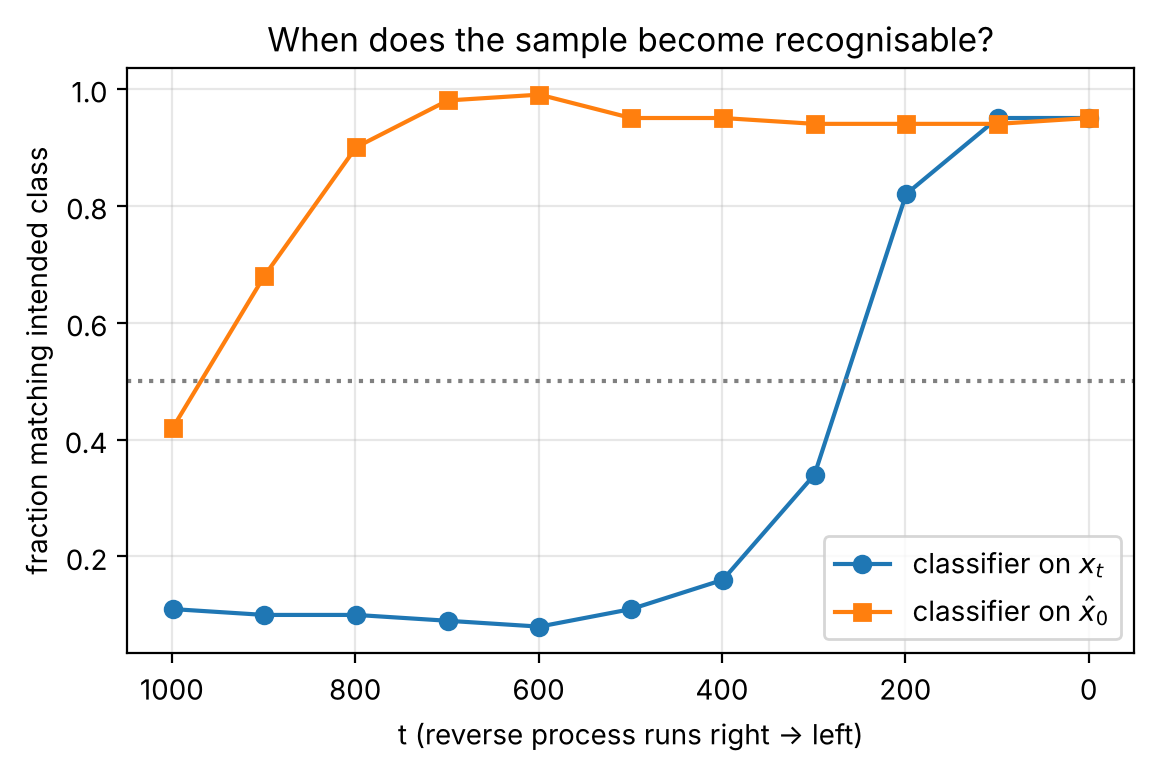

first recorded t where >=50% of x_t are classified correctly: 199 | of x0-estimates: 899


In [15]:
# When does class identity become detectable along the reverse trajectory?
acc_xt = [float((clf_probs(rec[tt][0]).argmax(1) == gen_labels).float().mean()) for tt in rec_ts]
acc_x0 = [float((clf_probs(rec[tt][1]).argmax(1) == gen_labels).float().mean()) for tt in rec_ts]
plt.figure(figsize=(6.5, 3.8))
plt.plot(rec_ts, acc_xt, "o-", label="classifier on $x_t$"); plt.plot(rec_ts, acc_x0, "s-", label="classifier on $\\hat{x}_0$")
plt.gca().invert_xaxis(); plt.xlabel("t (reverse process runs right -> left)"); plt.ylabel("fraction matching intended class")
plt.axhline(0.5, color="gray", ls=":"); plt.legend(); plt.grid(alpha=.3); plt.title("When does the sample become recognisable?")
savefig("recognisable_curve"); plt.show()
first_xt = next((tt for tt, a in zip(rec_ts, acc_xt) if a >= 0.5), None)
first_x0 = next((tt for tt, a in zip(rec_ts, acc_x0) if a >= 0.5), None)
RESULTS.update(first_t_xt_ge_50pct=first_xt, first_t_x0hat_ge_50pct=first_x0, acc_xt_by_t=dict(zip(map(int, rec_ts), acc_xt)), acc_x0hat_by_t=dict(zip(map(int, rec_ts), acc_x0)))
print("first recorded t where >=50% of x_t are classified correctly:", first_xt, "| of x0-estimates:", first_x0)

## 8. CLIP evaluation (optional, bonus 10%)

CLIP embeds images and text in one space; the cosine similarity between an image and a prompt such as *"a handwritten digit 7"* measures how well CLIP thinks the image matches. Two numbers per image: the **zero-shot probability on the intended class** (softmax over the 10 class prompts) and the **raw cosine similarity** to the intended prompt.

**Always compare against real test images.** CLIP is far from perfect on 28x28 digits, so the useful number is the *gap* between real and generated, not the absolute value.

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 31932.46it/s]

/tmp/ipykernel_749/3754067618.py:29: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  test_t = np.array(ds_test.targets)[test_idx]


            top-1 acc  P(target)  cos(target)
      real      0.360      0.148       0.2716
 generated      0.360      0.142       0.2772


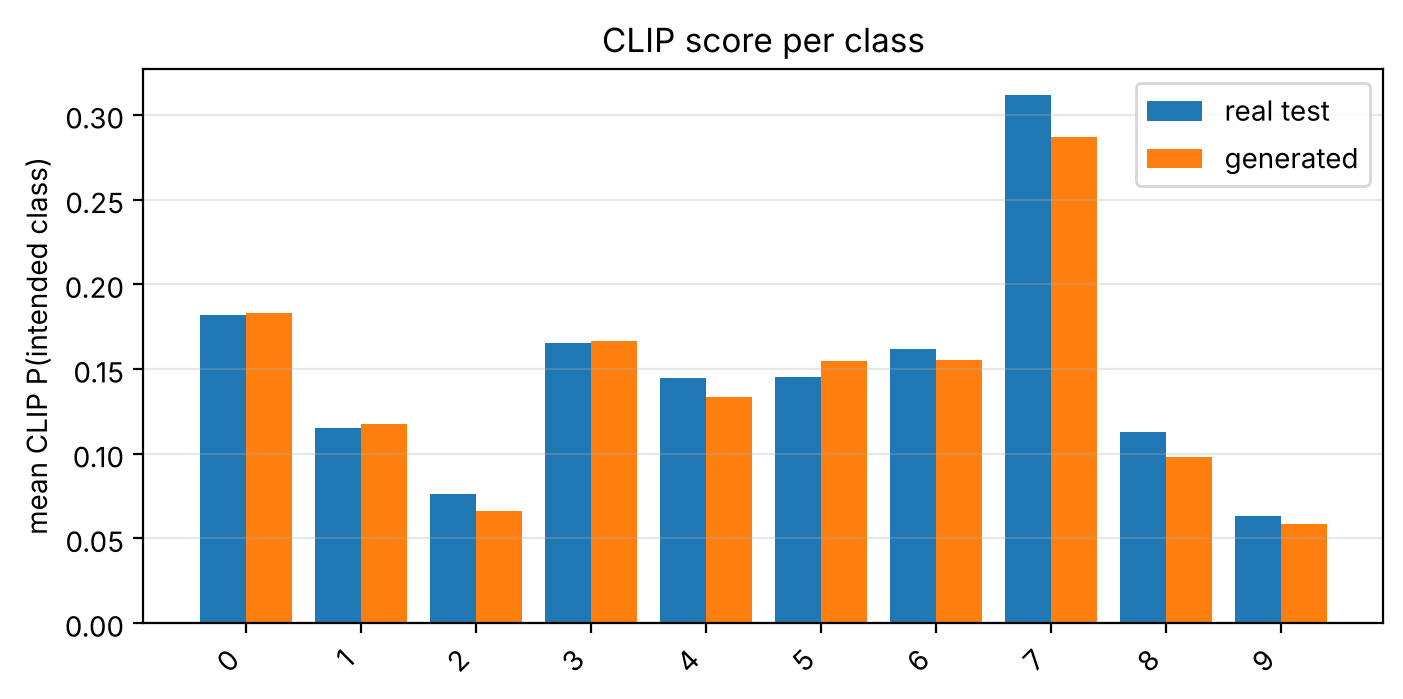

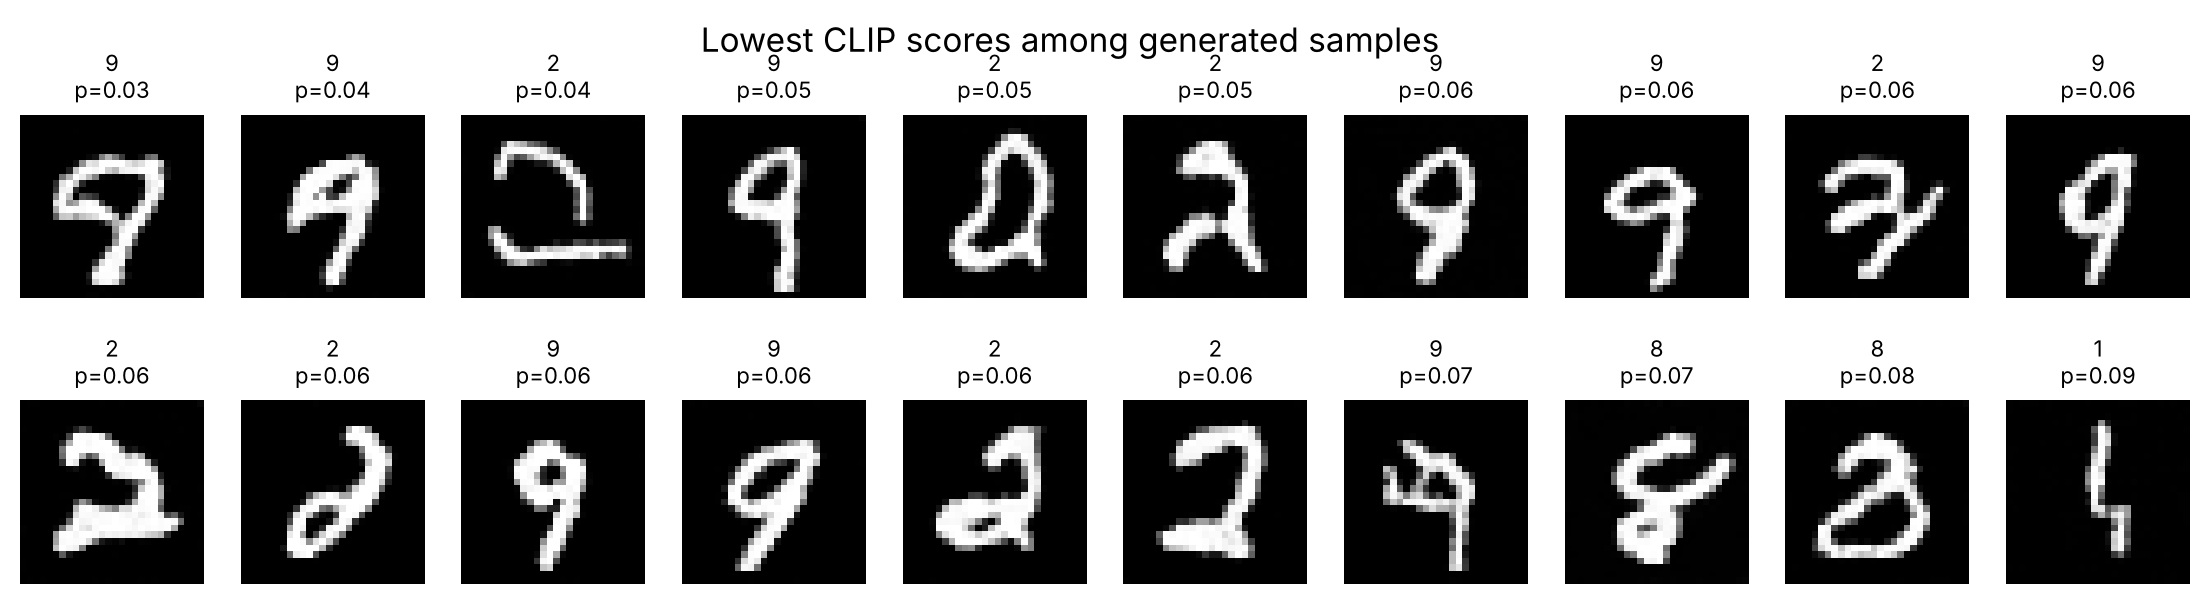

In [16]:
if RUN_CLIP:
    from transformers import CLIPModel, CLIPProcessor
    clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
    clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
    prompts = [PROMPT_TMPL[DATASET].format(n) for n in NAMES]
    to_pil = T.ToPILImage()

    def _tensor(o):
        if torch.is_tensor(o): return o
        for k in ("image_embeds", "text_embeds", "pooler_output"):
            if getattr(o, k, None) is not None: return getattr(o, k)
        return o[0]

    @torch.no_grad()
    def clip_eval(x, bs=64):
        """x in [-1,1], [N,C,H,W]. Returns (probs over class prompts [N,10], cosine sims [N,10])."""
        tin = clip_proc(text=prompts, return_tensors="pt", padding=True).to(device)
        txt = F.normalize(_tensor(clip.get_text_features(**tin)), dim=-1)
        P, S = [], []
        for i in range(0, len(x), bs):
            imgs = [to_pil(to01(xi)).convert("RGB") for xi in x[i:i + bs]]
            iin = clip_proc(images=imgs, return_tensors="pt").to(device)
            im = F.normalize(_tensor(clip.get_image_features(**iin)), dim=-1)
            sims = (im @ txt.T).float()
            S.append(sims.cpu()); P.append((100 * sims).softmax(-1).cpu())
        return torch.cat(P), torch.cat(S)

    # real baseline: first N_PER_CLASS test images of each class
    test_t = np.array(ds_test.targets)[test_idx]
    real_pick = np.concatenate([np.where(test_t == c)[0][:N_PER_CLASS] for c in range(NUM_CLASSES)])
    real_x, real_y = test_x[real_pick], test_y[real_pick]

    pr_real, sim_real = clip_eval(real_x)
    pr_gen, sim_gen = clip_eval(gen_imgs)
    def summarise(P, S, y):
        return dict(top1=float((P.argmax(1) == y).float().mean()),
                    mean_target_prob=float(P[torch.arange(len(y)), y].mean()),
                    mean_target_cosine=float(S[torch.arange(len(y)), y].mean()))
    cr, cg = summarise(pr_real, sim_real, real_y), summarise(pr_gen, sim_gen, gen_labels)
    RESULTS["clip_real"], RESULTS["clip_generated_w1"] = cr, cg
    print(f"{'':>10s} {'top-1 acc':>10s} {'P(target)':>10s} {'cos(target)':>12s}")
    print(f"{'real':>10s} {cr['top1']:10.3f} {cr['mean_target_prob']:10.3f} {cr['mean_target_cosine']:12.4f}")
    print(f"{'generated':>10s} {cg['top1']:10.3f} {cg['mean_target_prob']:10.3f} {cg['mean_target_cosine']:12.4f}")

    # per-class comparison
    pc_real = [float(pr_real[real_y == c, c].mean()) for c in range(NUM_CLASSES)]
    pc_gen = [float(pr_gen[gen_labels == c, c].mean()) for c in range(NUM_CLASSES)]
    RESULTS["clip_per_class_real"] = dict(zip(NAMES, [round(v, 3) for v in pc_real]))
    RESULTS["clip_per_class_generated"] = dict(zip(NAMES, [round(v, 3) for v in pc_gen]))
    xs = np.arange(NUM_CLASSES)
    plt.figure(figsize=(8, 3.6)); plt.bar(xs - .2, pc_real, .4, label="real test"); plt.bar(xs + .2, pc_gen, .4, label="generated")
    plt.xticks(xs, NAMES, rotation=45, ha="right"); plt.ylabel("mean CLIP P(intended class)"); plt.legend(); plt.grid(alpha=.3, axis="y")
    plt.title("CLIP score per class"); savefig("clip_per_class"); plt.show()

    # lowest-scoring generated samples, to look for failure patterns
    tp = pr_gen[torch.arange(len(gen_labels)), gen_labels]
    k = min(20, len(tp)); worst = tp.argsort()[:k]
    fig, axs = plt.subplots(2, 10, figsize=(14, 3.4))
    for a in axs.ravel(): a.axis("off")
    for j, idx in enumerate(worst.tolist()):
        a = axs[j // 10, j % 10]; a.imshow(to01(gen_imgs[idx]).permute(1, 2, 0).squeeze(), cmap="gray" if CH == 1 else None)
        a.set_title(f"{NAMES[gen_labels[idx]]}\np={tp[idx]:.2f}", fontsize=8)
    plt.suptitle("Lowest CLIP scores among generated samples"); savefig("clip_worst"); plt.show()

classifier-judged accuracy: all candidates 1.000 | CLIP-selected best-of-8 1.000  (only 10 selected images, so noisy)


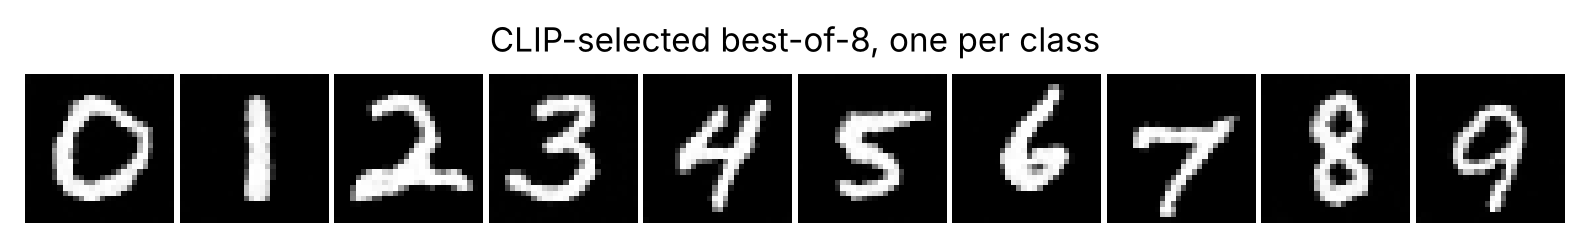

In [17]:
if RUN_CLIP:
    # Using CLIP to improve generation: best-of-N reranking.
    # Generate BON_N candidates per class (with guidance w=2), keep the one CLIP likes best.
    # Judge the result with the INDEPENDENT classifier, not CLIP itself, otherwise the test is circular.
    bon_labels = torch.arange(NUM_CLASSES).repeat_interleave(BON_N)
    cand = ddpm_sample(net, bon_labels, w=2.0, seed=777)
    p_c, _ = clip_eval(cand)
    sc = p_c[torch.arange(len(bon_labels)), bon_labels].view(NUM_CLASSES, BON_N)
    best = sc.argmax(1)
    chosen = torch.stack([cand[c * BON_N + int(best[c])] for c in range(NUM_CLASSES)])
    pred_all = clf_probs(cand).argmax(1)
    acc_all = float((pred_all == bon_labels).float().mean())
    acc_sel = float((clf_probs(chosen).argmax(1) == torch.arange(NUM_CLASSES)).float().mean())
    RESULTS["clip_best_of_n"] = dict(N=BON_N, classifier_acc_all_candidates=acc_all, classifier_acc_clip_selected=acc_sel)
    print(f"classifier-judged accuracy: all candidates {acc_all:.3f} | CLIP-selected best-of-{BON_N} {acc_sel:.3f}  (only 10 selected images, so noisy)")
    show_grid(chosen, 10, f"CLIP-selected best-of-{BON_N}, one per class", "clip_best_of_n", figsize=(10, 1.6))

## 9. Bonus challenges
The instructor's bonus list was not available to me when writing this, so I chose two that fit the model I already built: **(A) classifier-free guidance** and **(B) DDIM fast sampling**. If the real list differs, treat these as extra analysis in the report and swap in whichever listed challenge you attempt.

### 9A. Classifier-free guidance
Guided noise estimate: `eps = eps_uncond + w * (eps_cond - eps_uncond)`. Larger `w` pushes samples harder toward the class, usually raising class accuracy and lowering diversity. The sweep below measures both. Diversity is the mean per-pixel standard deviation across samples of the same class (a crude proxy; higher = more varied).

w = 1.0 | classifier-judged class accuracy 0.950 | diversity 0.2796


w = 2.0 | classifier-judged class accuracy 1.000 | diversity 0.2506


w = 3.0 | classifier-judged class accuracy 1.000 | diversity 0.2385


w = 5.0 | classifier-judged class accuracy 1.000 | diversity 0.2269


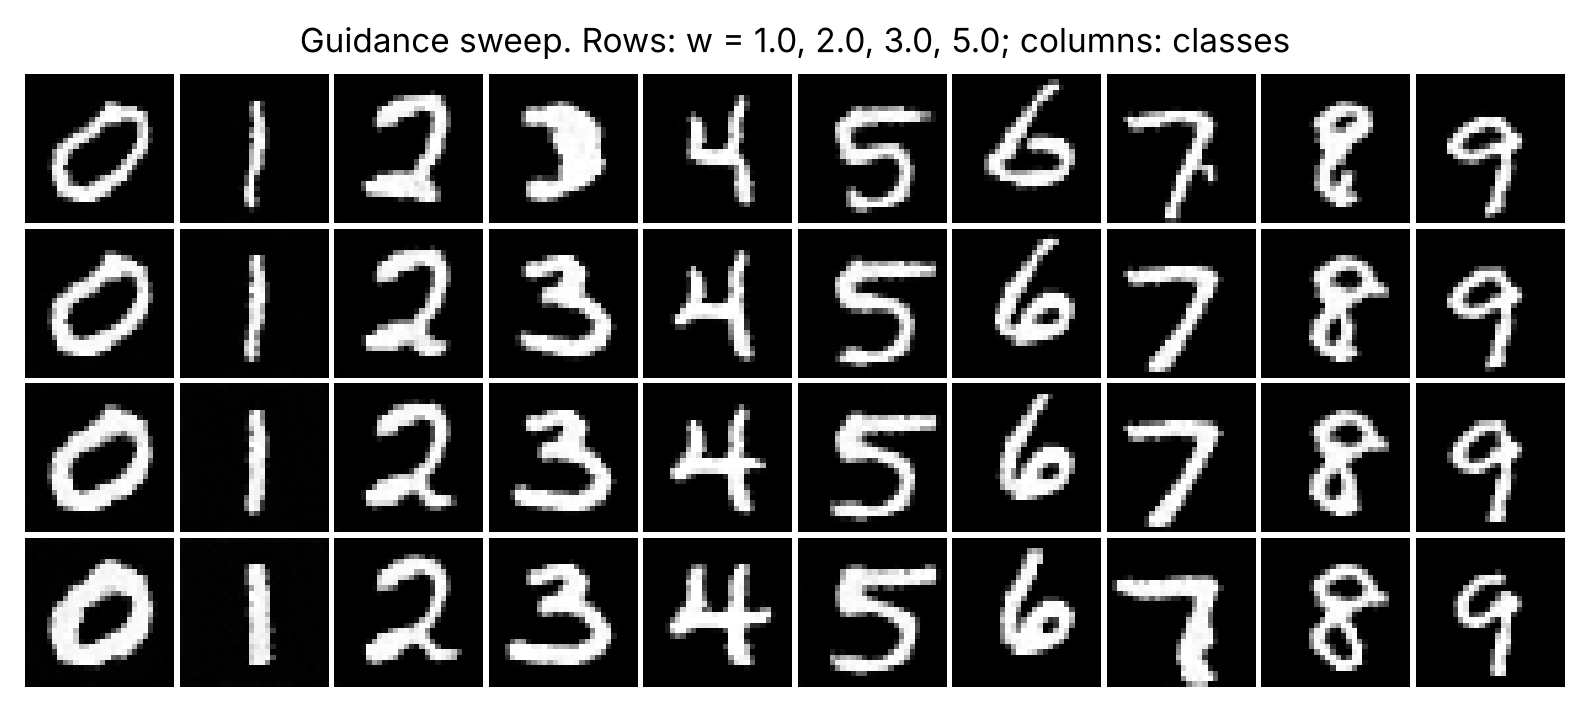

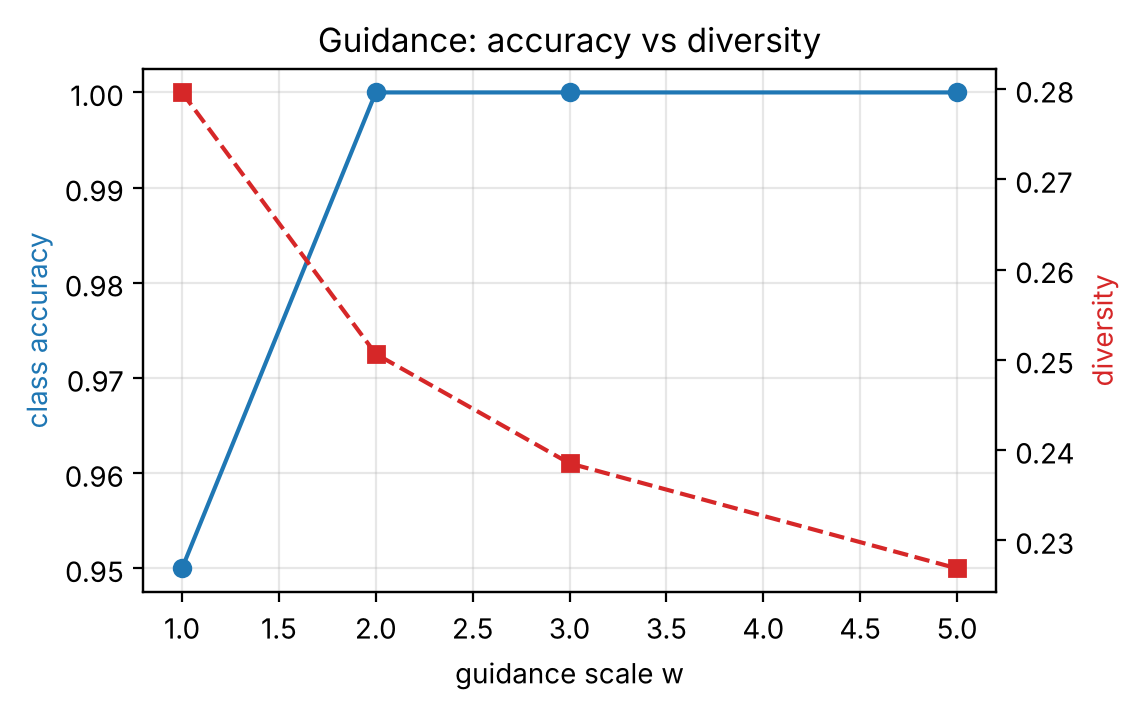

In [18]:
ws = [1.0, 2.0, 3.0, 5.0]
cfg_rows, cfg_first = [], []
sweep = {}
for w in ws:
    x = ddpm_sample(net, gen_labels, w=w, seed=2024)
    p = clf_probs(x).argmax(1)
    acc = float((p == gen_labels).float().mean())
    div = float(np.mean([x[gen_labels == c].std(0).mean().item() for c in range(NUM_CLASSES)]))
    sweep[w] = dict(class_acc=acc, diversity=div)
    cfg_first.append(torch.stack([x[c * N_PER_CLASS] for c in range(NUM_CLASSES)]))
    print(f"w = {w:3.1f} | classifier-judged class accuracy {acc:.3f} | diversity {div:.4f}")
RESULTS["cfg_sweep"] = {str(k): v for k, v in sweep.items()}
show_grid(torch.cat(cfg_first), NUM_CLASSES, "Guidance sweep. Rows: w = " + ", ".join(map(str, ws)) + "; columns: classes", "cfg_sweep", figsize=(10, 4.6))
fig, ax = plt.subplots(figsize=(5.5, 3.4)); ax2 = ax.twinx()
ax.plot(ws, [sweep[w]["class_acc"] for w in ws], "o-", color="C0"); ax2.plot(ws, [sweep[w]["diversity"] for w in ws], "s--", color="C3")
ax.set_xlabel("guidance scale w"); ax.set_ylabel("class accuracy", color="C0"); ax2.set_ylabel("diversity", color="C3"); ax.grid(alpha=.3)
plt.title("Guidance: accuracy vs diversity"); savefig("cfg_tradeoff"); plt.show()

### 9B. DDIM sampling (deterministic, far fewer steps)
DDIM reuses the *same trained network* but takes a deterministic path through a sub-sequence of timesteps: predict `x0`, re-derive the implied `eps`, and jump straight to the earlier timestep, `x_prev = sqrt(abar_prev) * x0_hat + sqrt(1 - abar_prev) * eps`. With 50 steps instead of 1000 it is about 20x faster; the question is what it costs in quality.

 DDPM 1000 |   101.8s | classifier-judged class accuracy 0.960
  DDIM 100 |    11.2s | classifier-judged class accuracy 0.930
   DDIM 50 |     5.2s | classifier-judged class accuracy 0.930
   DDIM 20 |     1.9s | classifier-judged class accuracy 0.940
   DDIM 10 |     1.1s | classifier-judged class accuracy 0.960


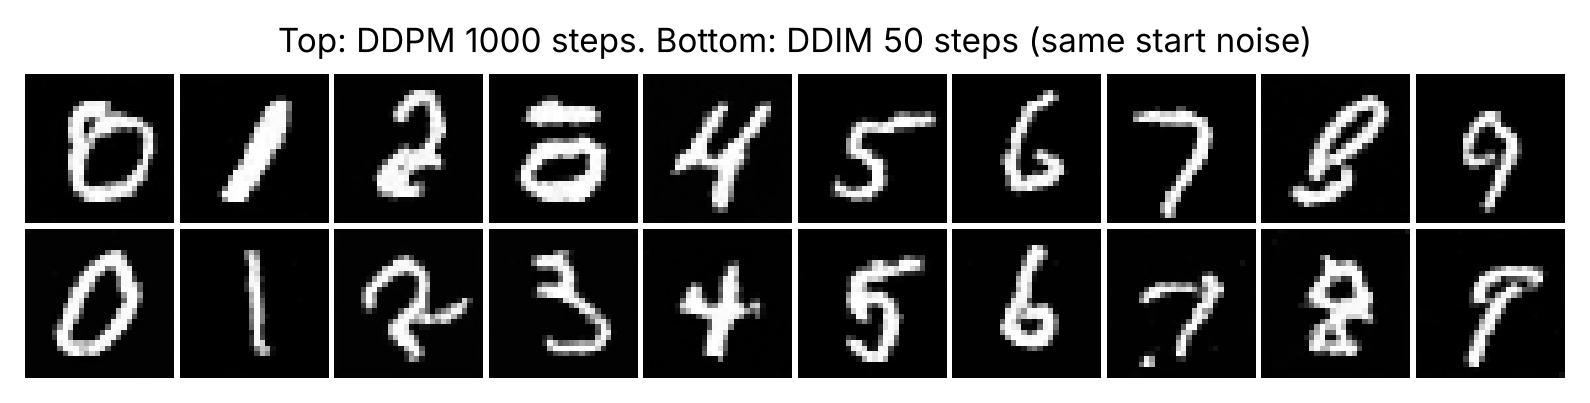

In [19]:
@torch.no_grad()
def ddim_sample(net, labels, steps=50, w=1.0, seed=None):
    net.eval()
    gen = torch.Generator(device=device).manual_seed(seed) if seed is not None else None
    labels = labels.to(device)
    x = torch.randn((len(labels), CH, SIZE, SIZE), device=device, generator=gen)
    ts = torch.linspace(T_STEPS - 1, 0, min(steps, T_STEPS)).long().tolist()
    for k, i in enumerate(ts):
        t = torch.full((len(x),), i, device=device, dtype=torch.long)
        eps = predict_eps(net, x, t, labels, w)
        x0 = ((x - sqrt_1m_abar[i] * eps) / sqrt_abar[i]).clamp(-1, 1)
        eps = (x - sqrt_abar[i] * x0) / sqrt_1m_abar[i]                       # re-derive eps consistent with the clipped x0
        ab_prev = abar[ts[k + 1]] if k + 1 < len(ts) else torch.tensor(1.0, device=device)
        x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * eps
    return x.clamp(-1, 1)

def timed(fn):
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time(); out = fn()
    if device.type == "cuda": torch.cuda.synchronize()
    return out, time.time() - t0

ddim_res = {}
x_ref, s_ref = timed(lambda: ddpm_sample(net, gen_labels, w=1.0, seed=5))
ddim_res[f"DDPM {T_STEPS}"] = dict(seconds=s_ref, class_acc=float((clf_probs(x_ref).argmax(1) == gen_labels).float().mean()))
for st in [100, 50, 20, 10]:
    x_d, s_d = timed(lambda: ddim_sample(net, gen_labels, steps=st, w=1.0, seed=5))
    ddim_res[f"DDIM {st}"] = dict(seconds=s_d, class_acc=float((clf_probs(x_d).argmax(1) == gen_labels).float().mean()))
    if st == 50: ddim50 = x_d
for k_, v in ddim_res.items(): print(f"{k_:>10s} | {v['seconds']:7.1f}s | classifier-judged class accuracy {v['class_acc']:.3f}")
RESULTS["ddim_vs_ddpm"] = ddim_res
show_grid(torch.cat([x_ref[::N_PER_CLASS], ddim50[::N_PER_CLASS]]), NUM_CLASSES, f"Top: DDPM {T_STEPS} steps. Bottom: DDIM 50 steps (same start noise)", "ddim_vs_ddpm", figsize=(10, 2.2))

## 10. Results summary (copy these numbers into the report)

In [20]:
RESULTS["parameters_M"] = RESULTS.get("parameters_M")
with open(f"figures/{DATASET}_results.json", "w") as f: json.dump(RESULTS, f, indent=2, default=str)
print(json.dumps(RESULTS, indent=2, default=str))
print("\nFigures saved in ./figures/. In Colab, to download everything:")
print("  !zip -qr figures.zip figures && python -c \"from google.colab import files; files.download('figures.zip')\"")

{
  "dataset": "MNIST",
  "epochs": 10,
  "T": 1000,
  "base_channels": 32,
  "batch_size": 128,
  "lr": 0.0002,
  "parameters_M": 0.733,
  "final_train_loss": 0.024727804590633142,
  "final_val_loss": 0.023934569066884567,
  "train_minutes": 33.3,
  "ddpm_sample_seconds": 99.7,
  "classifier_test_acc": 0.9918000102043152,
  "gen_class_acc_w1": 0.949999988079071,
  "gen_class_acc_per_class_w1": {
    "0": 1.0,
    "1": 1.0,
    "2": 0.9,
    "3": 0.8,
    "4": 1.0,
    "5": 0.9,
    "6": 1.0,
    "7": 0.9,
    "8": 1.0,
    "9": 1.0
  },
  "first_t_xt_ge_50pct": 199,
  "first_t_x0hat_ge_50pct": 899,
  "acc_xt_by_t": {
    "999": 0.10999999940395355,
    "899": 0.10000000149011612,
    "799": 0.10000000149011612,
    "699": 0.09000000357627869,
    "599": 0.07999999821186066,
    "499": 0.10999999940395355,
    "399": 0.1599999964237213,
    "299": 0.3400000035762787,
    "199": 0.8199999928474426,
    "99": 0.949999988079071,
    "0": 0.949999988079071
  },
  "acc_x0hat_by_t": {
    "9

## 11. Assessment questions: where the evidence for each answer is

The written answers go in the report PDF (`MD_Report_Trilok_Kalani_ITAI.pdf`). Use these notebook outputs as the evidence:

| Question | Evidence in this notebook |
|---|---|
| 1. Understanding diffusion | Forward-process figure and schedule plot (section 2); step-by-step generation figures and the "recognisable" curve (section 7) |
| 2. Architecture | Section 3 code and its comments; FiLM + null-token class conditioning |
| 3. Training analysis | Loss and gradient-norm plots, training-progress grid (section 6) |
| 4. CLIP | Section 8 tables and charts, worst-sample gallery, best-of-N result; classifier confusion matrix (section 7b) |
| 5. Applications and limits | Run times, parameter count, guidance trade-off, DDIM trade-off (sections 9, 10) |
| 6. Bonus | Guidance sweep (9A), DDIM vs DDPM (9B) |